# Waktu pengambilan gambar pada tiap kultivasi untuk FOTO1

In [38]:

#! Import Libraries
from pathlib import Path
from datetime import datetime
import re
from collections import Counter

import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [ ]:
ROOT = Path("Data Kultivasi Mikroalga K1-16/foto")
EXTENSIONS = {".jpg"}

total_foto = 0
jumlah_per_kultivasi = {}

folders = sorted(p for p in ROOT.iterdir() if p.is_dir())

for folder in folders:
    foto1 = next(
        (p for p in folder.iterdir()
        if p.is_dir() and p.name.casefold() == "foto1"),
        None
    )
    
    jumlah = (
        sum(
            1 for file in foto1.iterdir()
            if file.is_file() and file.suffix.lower() in EXTENSIONS
        )
        if foto1 else 0
    )
    
    files = list(foto1.glob("*"))
    print(folder.name, "->", foto1, "| jumlah file:", len(files))
    print("  contoh:", [f.name for f in files[:2]])
    
    jumlah_per_kultivasi[folder.name] = jumlah
    total_foto += jumlah

print("Jumlah folder kultivasi:", len(folders))
print(f"Total foto: {total_foto:,}")



K01 -> Data Kultivasi Mikroalga K1-16\foto\K01\FOTO1 | jumlah file: 3854
  contoh: ['obsbot_photo_20250813_111811_601_3840x2160.jpg', 'obsbot_photo_20250813_112551_217_3840x2160.jpg']
K02 -> Data Kultivasi Mikroalga K1-16\foto\K02\FOTO1 | jumlah file: 5947
  contoh: ['obsbot_photo_20250912_140509_3840x2160.jpg', 'obsbot_photo_20250912_141004_3840x2160.jpg']
K03 -> Data Kultivasi Mikroalga K1-16\foto\K03\FOTO1 | jumlah file: 1169
  contoh: ['obsbot_photo_20251016_150505_3840x2160.jpg', 'obsbot_photo_20251016_151005_3840x2160.jpg']
K04 -> Data Kultivasi Mikroalga K1-16\foto\K04\FOTO1 | jumlah file: 6310
  contoh: ['obsbot_photo_20251020_163005_3840x2160.jpg', 'obsbot_photo_20251020_163505_3840x2160.jpg']
K05 -> Data Kultivasi Mikroalga K1-16\foto\K05\FOTO1 | jumlah file: 4139
  contoh: ['obsbot_photo_20251111_060005_3840x2160.jpg', 'obsbot_photo_20251111_060505_3840x2160.jpg']
K06 -> Data Kultivasi Mikroalga K1-16\foto\K06\FOTO1 | jumlah file: 4006
  contoh: ['obsbot_photo_20251204_17153

In [40]:
ROOT = Path("Data Kultivasi Mikroalga K1-16/foto")
OUTPUT_DIR = Path("D:\\00 Kuliah\\TA\\Experiment\\Eksplorasi data\\grafik_per_kultivasi")

extensions = {".jpg", ".jpeg", ".png"}

#! Pola timestamp pada nama file: _YYYYMMDD_HHMMSS_mmm_
timestamp_pattern = re.compile(
    r"_(\d{8})_(\d{6})(?:_(\d{3}))?_"
)

folders = sorted(
    (p for p in ROOT.iterdir() if p.is_dir()),
    key=lambda p: p.name
)


K01: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K01_timestamp.png


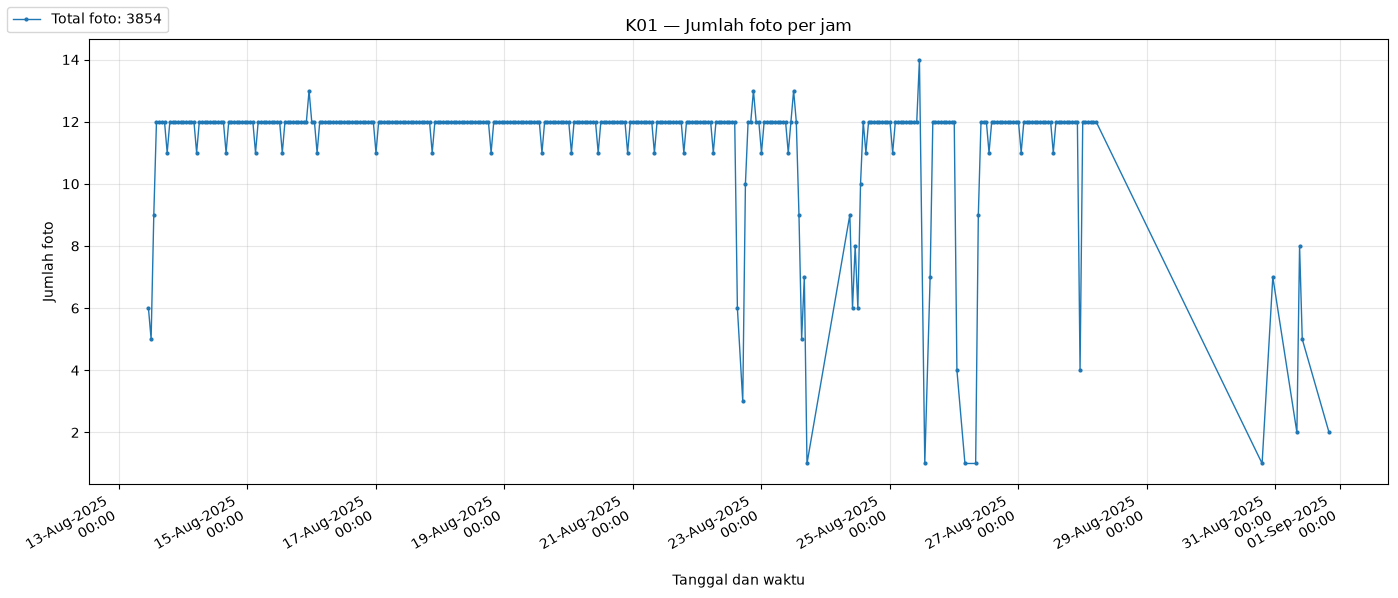

K02: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K02_timestamp.png


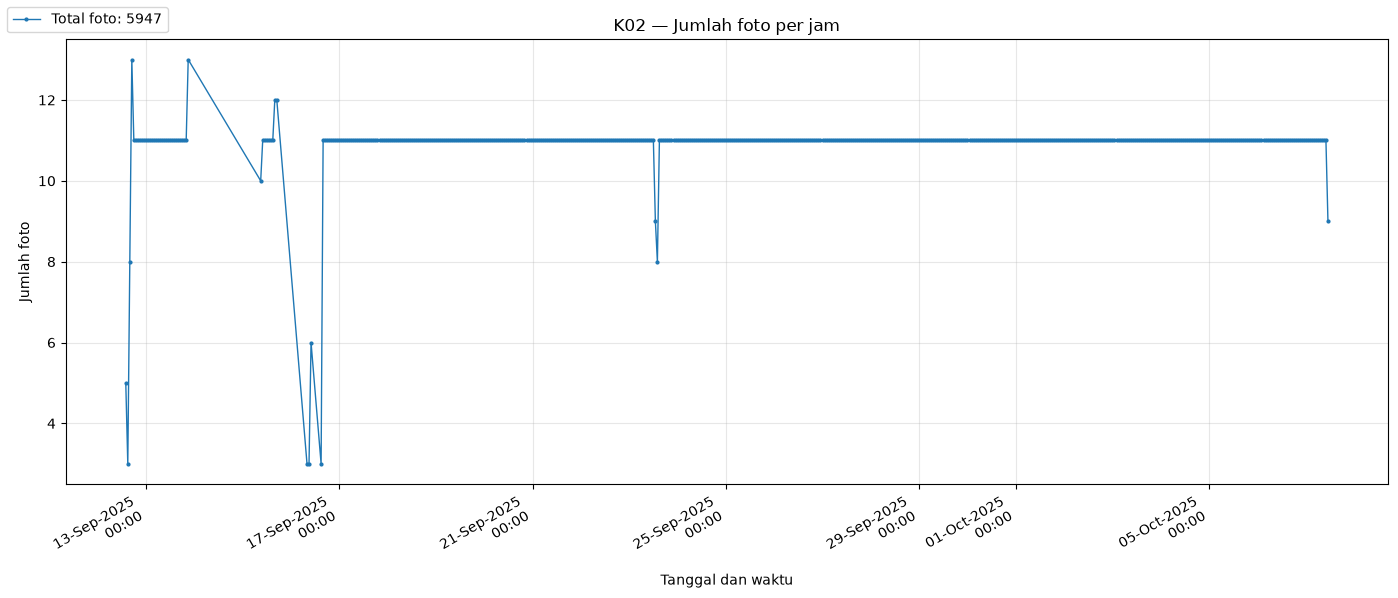

K03: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K03_timestamp.png


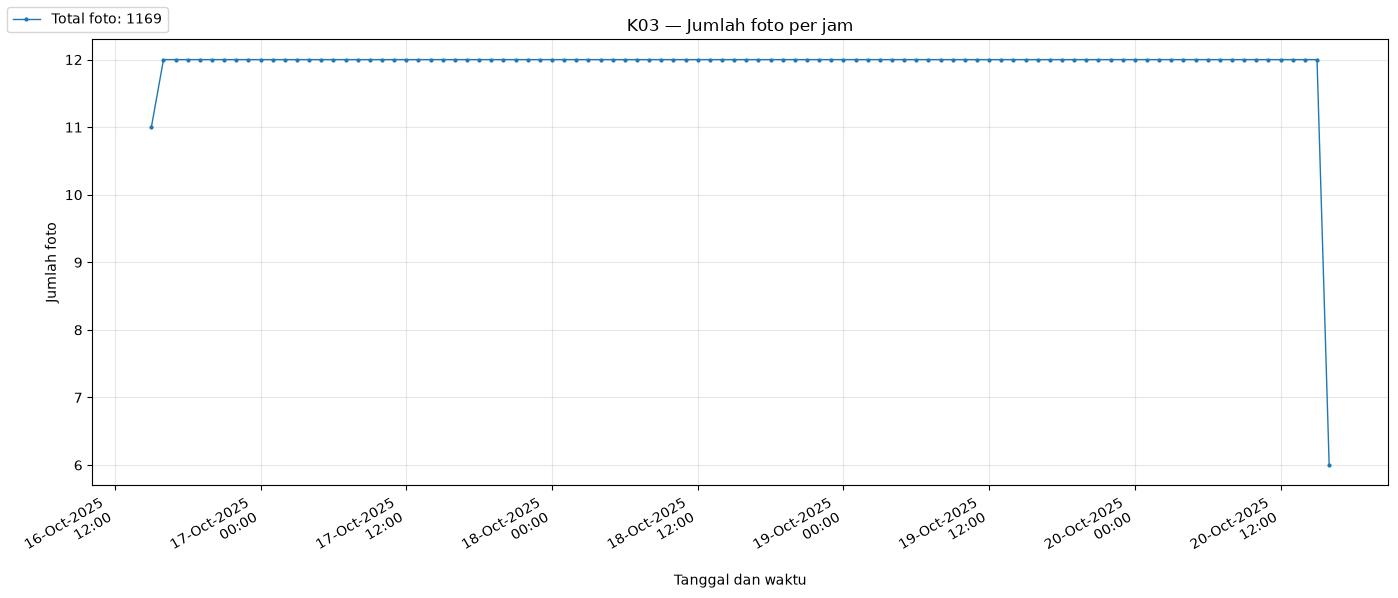

K04: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K04_timestamp.png


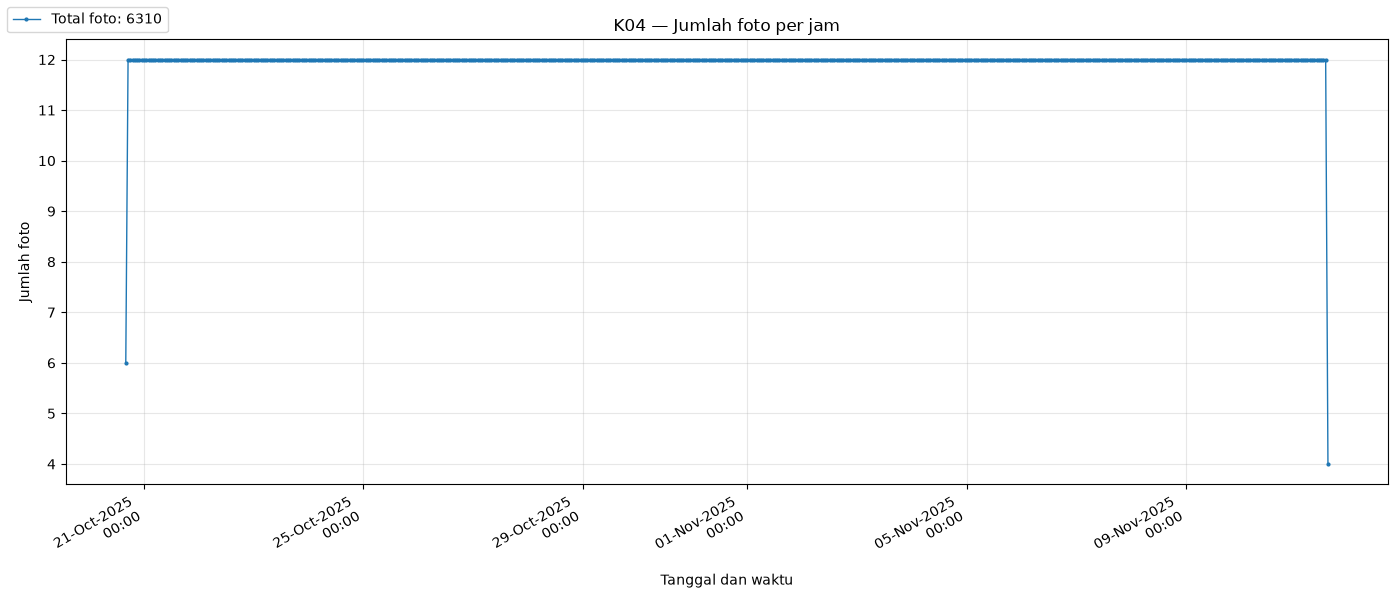

K05: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K05_timestamp.png


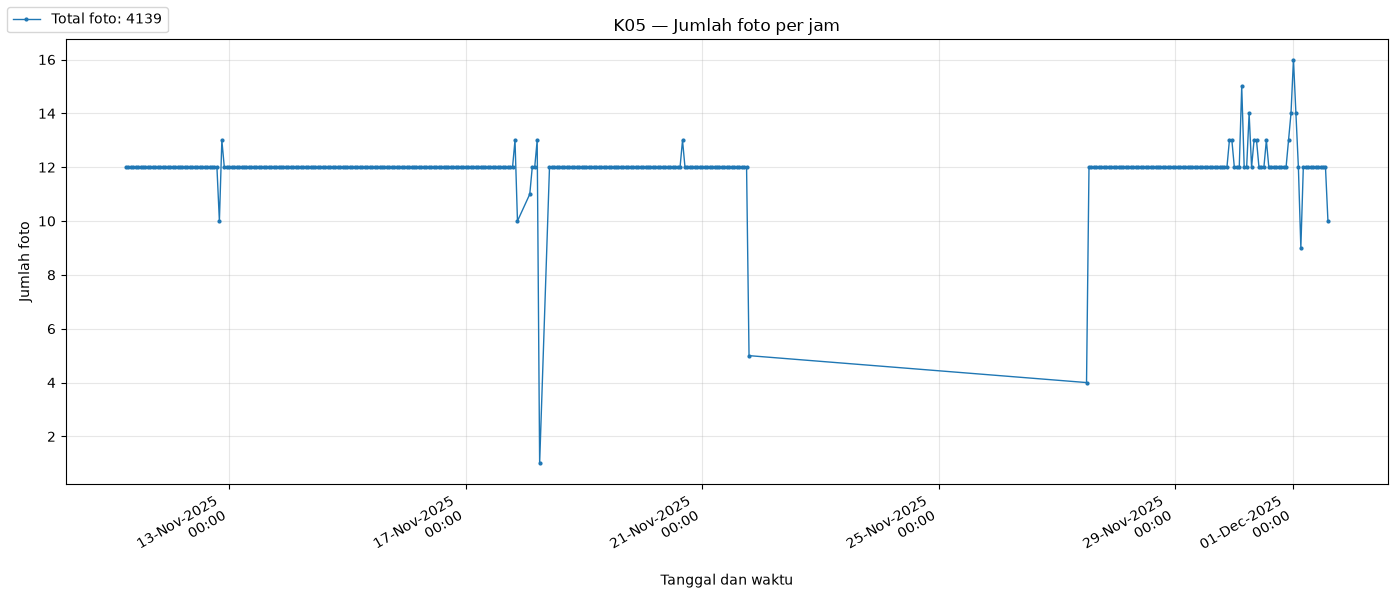

K06: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K06_timestamp.png


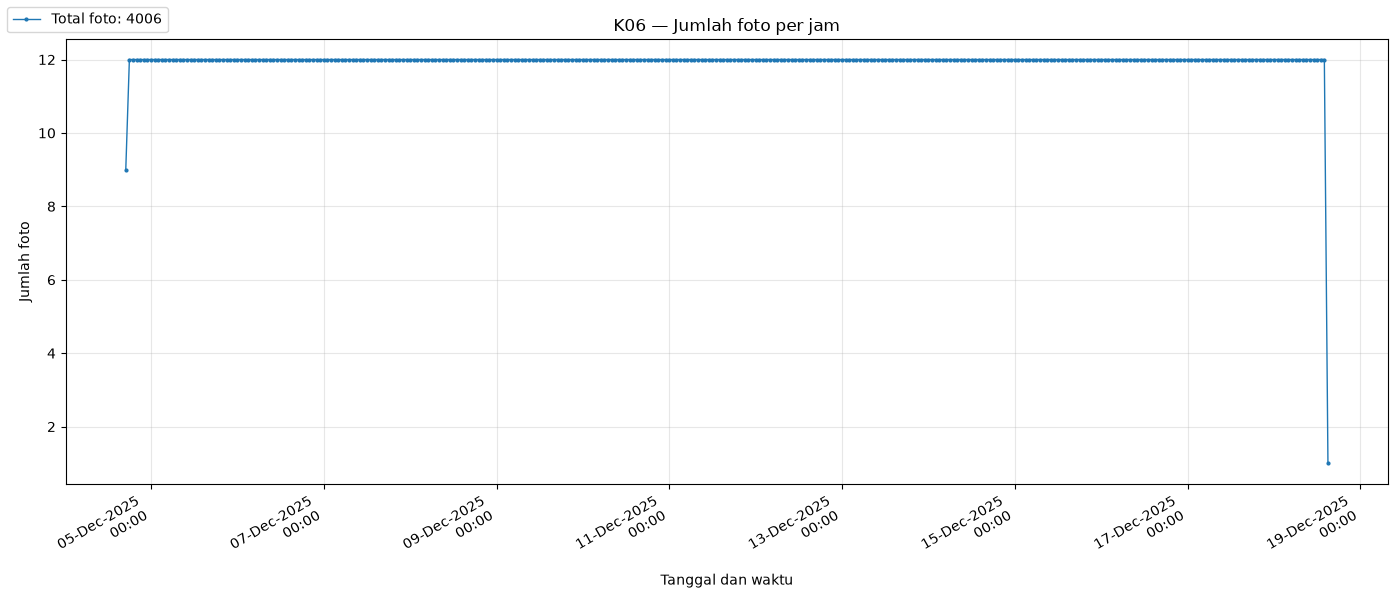

K07: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K07_timestamp.png


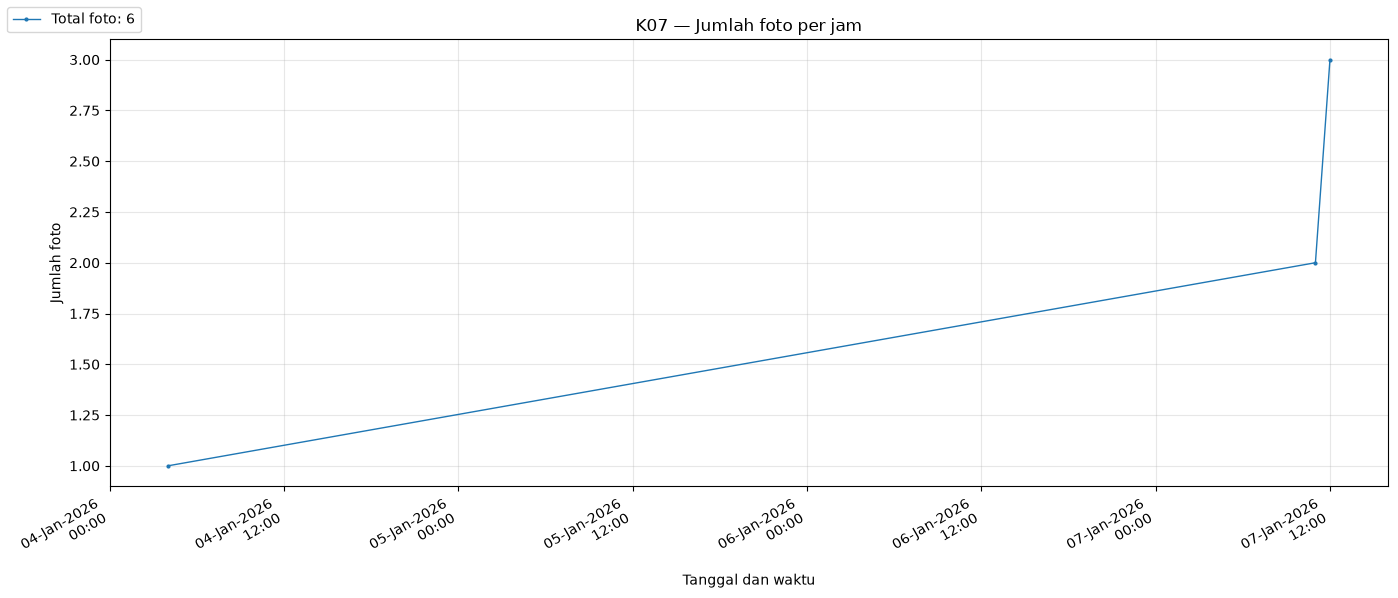

K08: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K08_timestamp.png


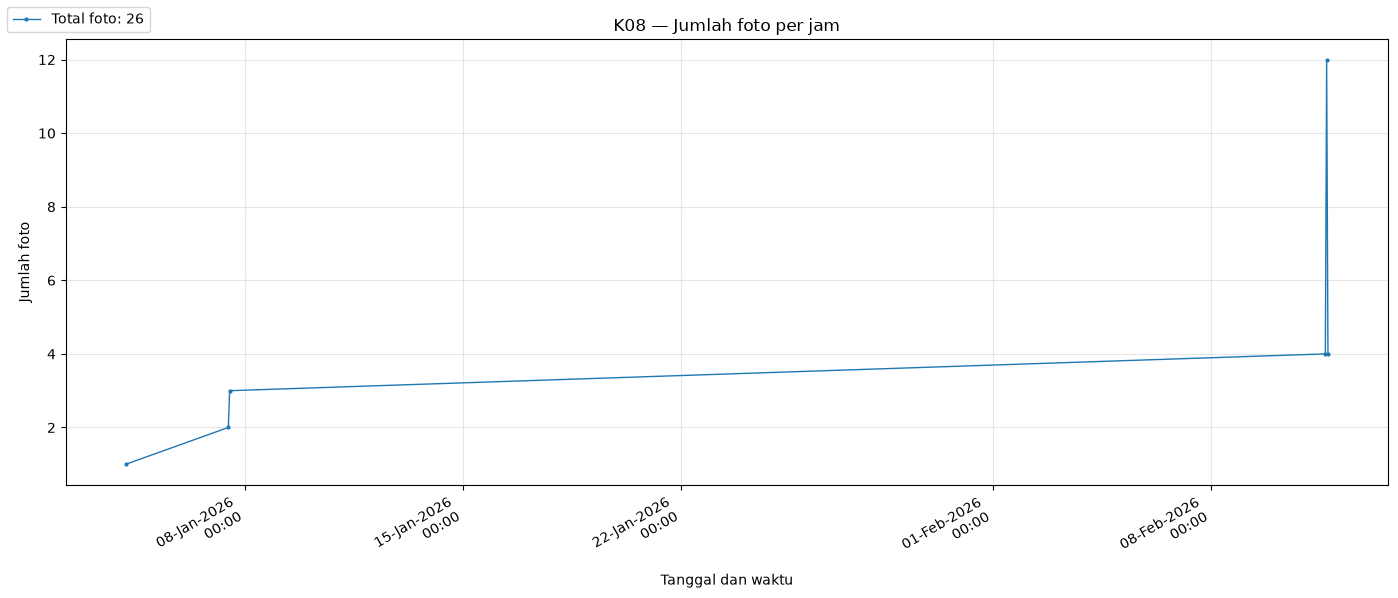

K09: tidak ada foto.
K10: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K10_timestamp.png


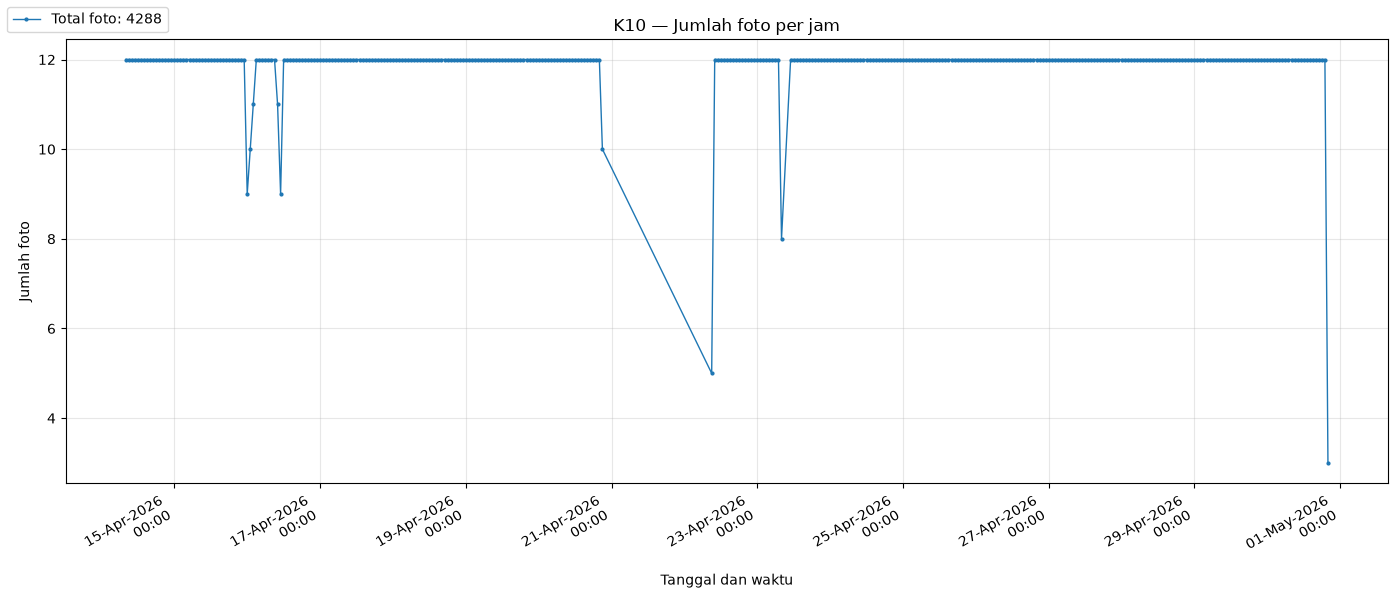

K11: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K11_timestamp.png


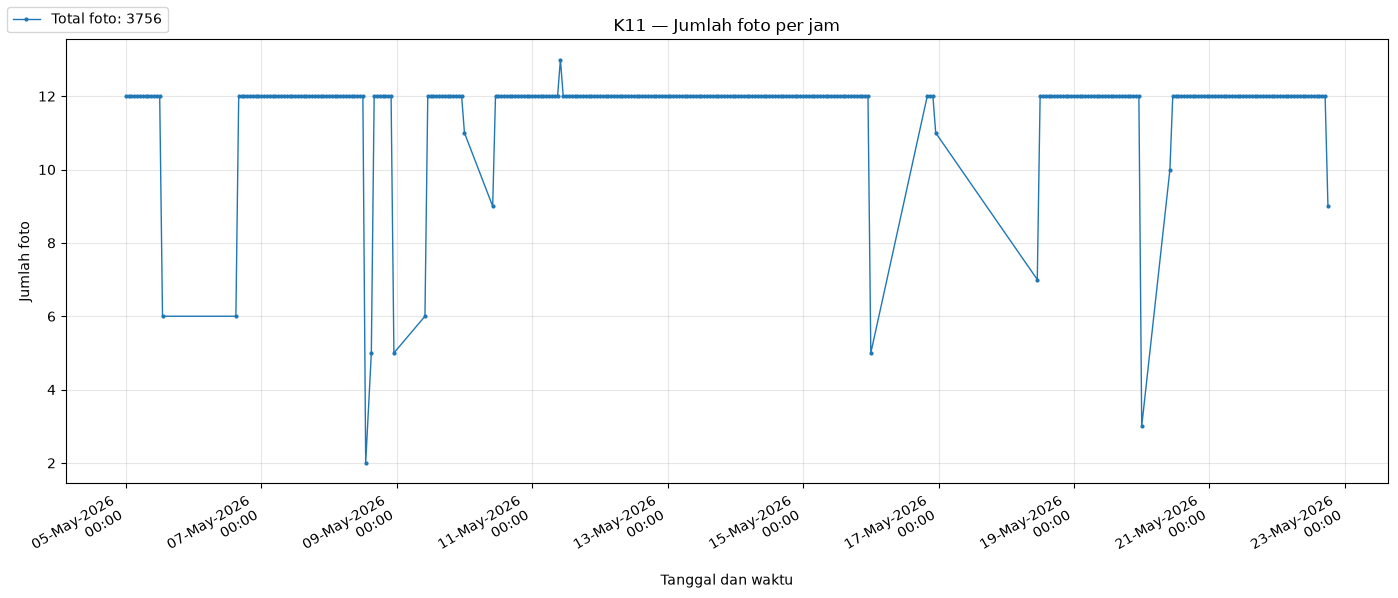

K12: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K12_timestamp.png


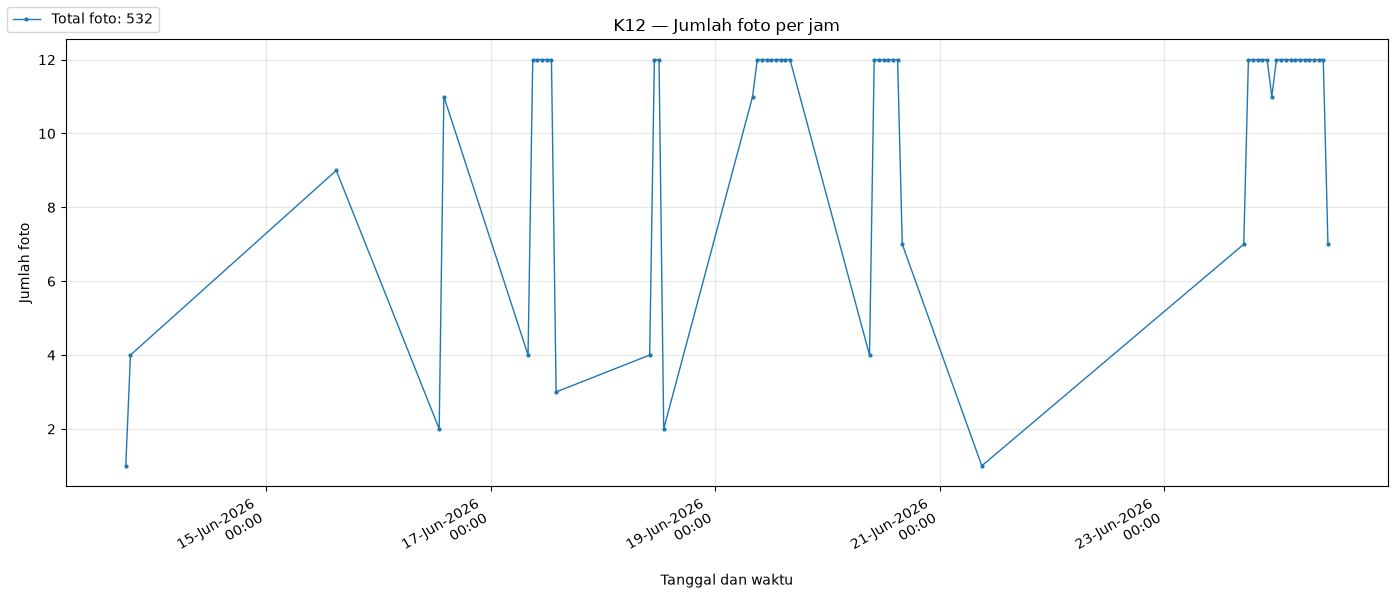

K13: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K13_timestamp.png


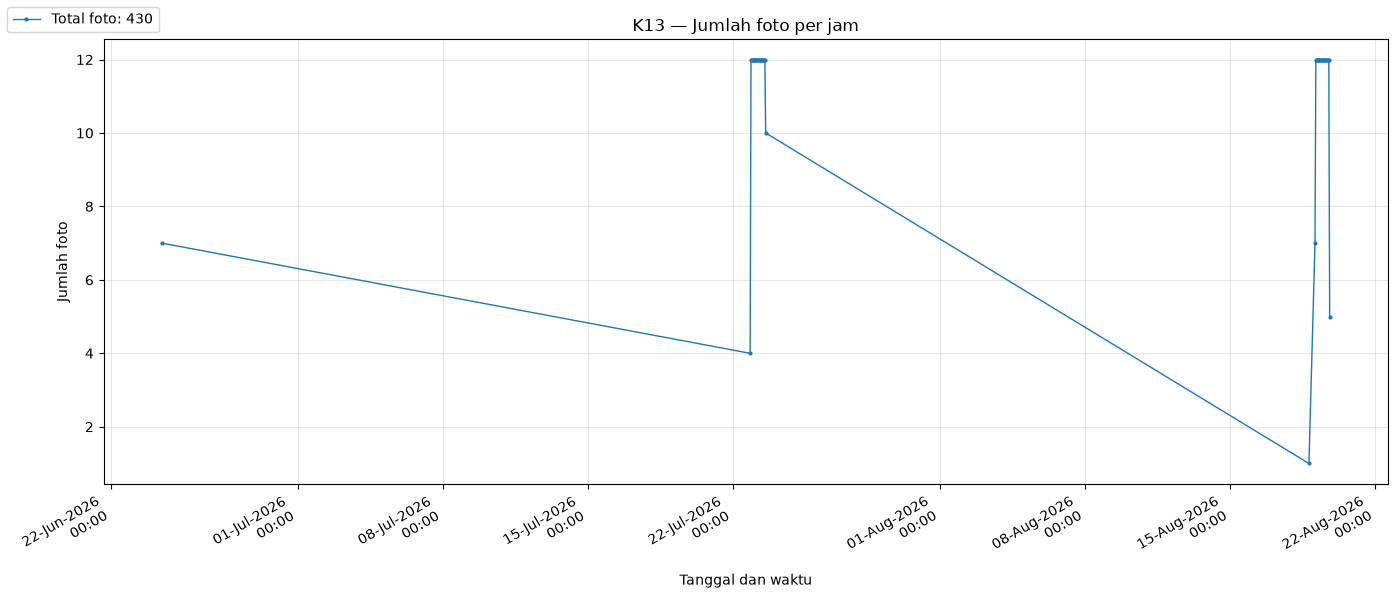

K14: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K14_timestamp.png


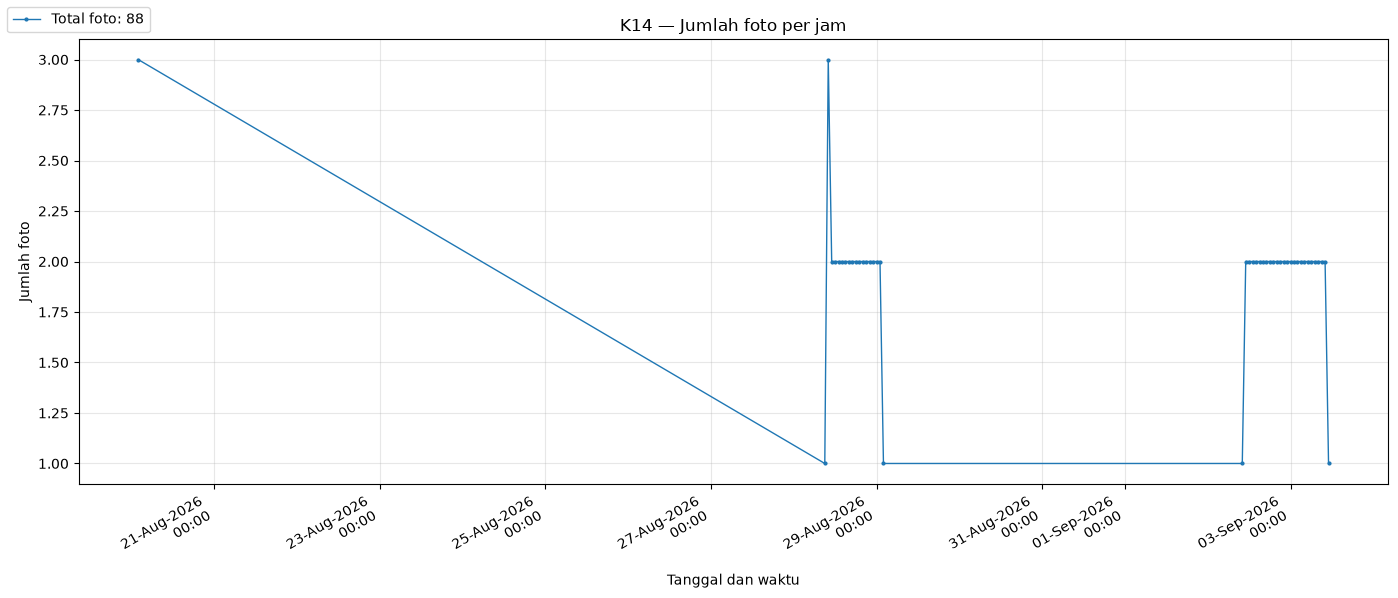

K15: grafik disimpan ke D:\00 Kuliah\TA\Experiment\Eksplorasi data\grafik_per_kultivasi\K15_timestamp.png


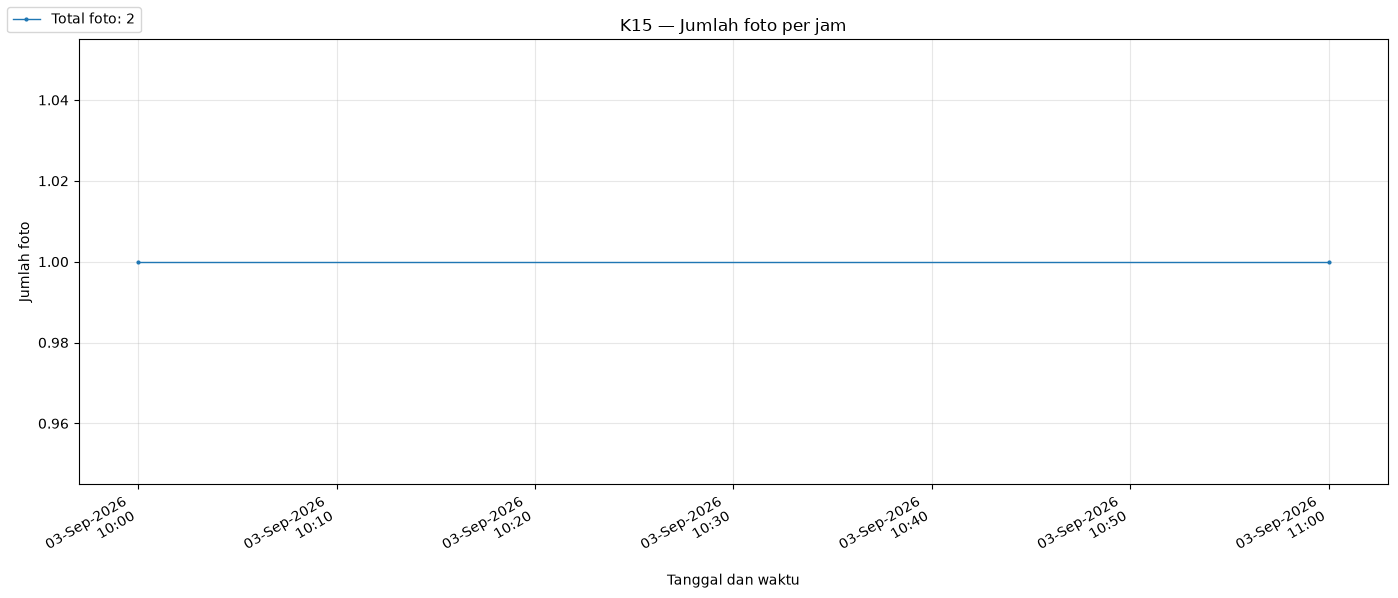

K16: tidak ada foto.


In [41]:
for folder in folders:
    foto1 = next(
        (p for p in folder.iterdir()
         if p.is_dir() and p.name.casefold() == "foto1"),
        None
    )

    timestamps = []

    if foto1:
        for file in foto1.iterdir():
            if not file.is_file() or file.suffix.lower() not in EXTENSIONS:
                continue

            match = timestamp_pattern.search(file.stem)
            if not match:
                continue

            tanggal, waktu, milidetik = match.groups()
            nilai = f"{tanggal}_{waktu}"
            fmt = "%Y%m%d_%H%M%S"

            if milidetik:
                nilai += f"_{milidetik}"
                fmt += "_%f"

            timestamps.append(datetime.strptime(nilai, fmt))

    if not timestamps:
        print(f"{folder.name}: tidak ada foto.")
        continue

    # Hitung jumlah foto per jam
    jumlah_per_jam = Counter(
        t.replace(minute=0, second=0, microsecond=0)
        for t in timestamps
    )
    waktu = sorted(jumlah_per_jam)

    fig, ax = plt.subplots(figsize=(14, 6))
    ax.plot(
        waktu,
        [jumlah_per_jam[t] for t in waktu],
        marker=".",
        markersize=4,
        linewidth=1
    )

    ax.set_title(f"{folder.name} — Jumlah foto per jam")
    ax.set_xlabel("Tanggal dan waktu")
    ax.set_ylabel("Jumlah foto")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b-%Y\n%H:%M"))
    ax.grid(True, alpha=0.3)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.legend([f"Total foto: {len(timestamps)}"], loc="upper left")

    output_file = OUTPUT_DIR / f"{folder.name}_timestamp.png"
    fig.savefig(output_file, dpi=200, bbox_inches="tight")
    print(f"{folder.name}: grafik disimpan ke {output_file}")

    plt.show()
    plt.close(fig)

# Waktu pengambilan sensor pada tiap kultivasi pada sensor Lab Analog

In [62]:

#! Import Libraries
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import pandas as pd
import re

ROOT = Path("Dataset/Data Sensor Kultivasi/csv/Lab Analog K1-K16")
parameter = "Optical density (AU) (680 nm).Lab"

#! Baca semua CSV
data = {}

In [63]:
NAMA_BULAN = {
    "januari": "01", "februari": "02", "maret": "03",
    "april": "04", "mei": "05", "juni": "06",
    "juli": "07", "agustus": "08", "september": "09",
    "oktober": "10", "november": "11", "desember": "12",
}

def parse_tanggal(nilai):
    if pd.isna(nilai):
        return pd.NaT

    teks = str(nilai).strip()

    # Format ISO, misalnya 2026-05-13
    tanggal = pd.to_datetime(teks, format="%Y-%m-%d", errors="coerce")
    if pd.notna(tanggal):
        return tanggal

    # Format Indonesia, misalnya 24 Juli 2026
    cocok = re.fullmatch(r"(\d{1,2})\s+([A-Za-z]+)\s+(\d{4})", teks)
    if cocok:
        hari, bulan, tahun = cocok.groups()
        nomor_bulan = NAMA_BULAN.get(bulan.casefold())
        if nomor_bulan:
            return pd.to_datetime(
                f"{tahun}-{nomor_bulan}-{int(hari):02d}",
                format="%Y-%m-%d",
                errors="coerce"
            )

    return pd.NaT

In [64]:
for file in sorted(ROOT.glob("*.csv")):

    nomor = int(file.name.split("_")[0].replace("Kultivasi ", ""))

    df = pd.read_csv(file)
    df.columns = df.columns.str.strip()
    data[nomor] = df
    
# Periksa file kultivasi yang tidak ditemukan
tidak_ada = sorted(set(range(1, 17)) - set(data))
print("Kultivasi tanpa file CSV:", tidak_ada)

Kultivasi tanpa file CSV: [15]


In [65]:
# Ringkasan jumlah baris dan kolom
ringkasan = pd.DataFrame([
    {
        "Kultivasi": f"K{k:02}",
        "Jumlah baris": len(df),
        "Jumlah kolom": len(df.columns),
    }
    for k, df in sorted(data.items())
])
display(ringkasan)

,Kultivasi,Jumlah baris,Jumlah kolom
0,K01,17,23
1,K02,26,23
2,K03,5,23
3,K04,23,23
4,K05,15,23
5,K06,15,23
6,K07,17,23
7,K08,15,23
8,K09,16,23
9,K10,16,23


In [66]:
# Lihat kolom dan contoh isi dari salah satu file
print("Kolom:", list(data[min(data)].columns))
display(data[min(data)].head())

Kolom: ['Hari', 'Tanggal', 'Waktu (jam:menit:detik)', 'COD (mg/L).Lab', 'BOD (mg/L).Lab', 'Optical density (AU) (680 nm).Lab', 'pH.analog', 'DO (ppm).analog', 'TDS (ppm).analog', 'Suhu air (C).analog', 'Intensitas cahaya (lux).analog', 'Suhu udara (C).analog', 'Kelembapan udara (%).analog', 'Tekanan udara (Pa).analog', 'EC (us/cm).analog', 'Specific Gravity.analog', 'Salinity (%).analog', 'ORP (mV).analog', 'Aerasi (jam).treatment', 'Sodium Bikarbonat (mL).treatment', 'Microalgae (mL).treatment', 'molase (mL).treatment', 'Intensitas cahaya (jam).treatment']


,Hari,Tanggal,Waktu (jam:menit:detik),COD (mg/L).Lab,BOD (mg/L).Lab,Optical density (AU) (680 nm).Lab,pH.analog,DO (ppm).analog,TDS (ppm).analog,Suhu air (C).analog,...,Tekanan udara (Pa).analog,EC (us/cm).analog,Specific Gravity.analog,Salinity (%).analog,ORP (mV).analog,Aerasi (jam).treatment,Sodium Bikarbonat (mL).treatment,Microalgae (mL).treatment,molase (mL).treatment,Intensitas cahaya (jam).treatment
0,0,2025-08-14,16:10:00,1011.5,505.75,0.8200,7.98,1.24,1780,2025-05-29 00:00:00,...,1,5126,1001,0.33,-100,8,7.5,0,0.0,8
1,1,2025-08-15,11:16:00,679.0,339.50,0.6725,2025-02-09 00:00:00,2025-01-01 00:00:00,1524,34,...,1,5224,1002,0.35,-98,24,0.0,0,0.0,24
2,2,2025-08-16,11:20:00,592.0,296.00,0.5157,9.51,2025-06-01 00:00:00,1528,34,...,1,5782,1004,0.40,-99,12,0.0,0,0.0,24
3,3,2025-08-17,11:12:00,505.0,252.50,0.3590,9.36,2025-04-01 00:00:00,1509,33,...,1,6041,1004,0.39,-102,24,0.0,0,0.0,24
4,4,2025-08-18,10:26:00,502.0,251.00,0.3630,8.96,2025-03-01 00:00:00,1495,33,...,1,6423,1002,0.37,-82,12,0.0,0,0.0,24


In [67]:
# Cek nilai kosong dan tipe data setiap kolom
for k, df in sorted(data.items()):
    print(f"\nK{k:02}")
    display(pd.DataFrame({
        "Tipe data": df.dtypes.astype(str),
        "Jumlah kosong": df.isna().sum(),
        "Jumlah nilai unik": df.nunique(dropna=True),
    }))



K01


,Tipe data,Jumlah kosong,Jumlah nilai unik
Hari,int64,0,17
Tanggal,str,0,17
Waktu (jam:menit:detik),str,0,12
COD (mg/L).Lab,float64,0,17
BOD (mg/L).Lab,float64,0,17
Optical density (AU) (680 nm).Lab,float64,0,17
pH.analog,str,0,12
DO (ppm).analog,str,0,14
TDS (ppm).analog,int64,0,16
Suhu air (C).analog,str,0,7



K02


,Tipe data,Jumlah kosong,Jumlah nilai unik
Hari,int64,0,26
Tanggal,str,0,26
Waktu (jam:menit:detik),str,0,22
COD (mg/L).Lab,float64,0,26
BOD (mg/L).Lab,float64,0,26
Optical density (AU) (680 nm).Lab,float64,0,23
pH.analog,float64,0,21
DO (ppm).analog,float64,0,21
TDS (ppm).analog,int64,0,26
Suhu air (C).analog,float64,0,19



K03


,Tipe data,Jumlah kosong,Jumlah nilai unik
Hari,int64,0,5
Tanggal,str,0,5
Waktu (jam:menit:detik),str,0,5
COD (mg/L).Lab,int64,0,5
BOD (mg/L).Lab,float64,0,5
Optical density (AU) (680 nm).Lab,float64,0,4
pH.analog,float64,0,5
DO (ppm).analog,float64,0,4
TDS (ppm).analog,int64,0,5
Suhu air (C).analog,float64,0,4


... (20 outputs left out)


K14


,Tipe data,Jumlah kosong,Jumlah nilai unik
Hari,int64,0,15
Tanggal,str,0,15
Waktu (jam:menit:detik),str,0,7
COD (mg/L).Lab,int64,0,15
BOD (mg/L).Lab,float64,0,15
Optical density (AU) (680 nm).Lab,float64,0,15
pH.analog,float64,0,14
DO (ppm).analog,float64,0,11
TDS (ppm).analog,int64,0,15
Suhu air (oC).analog,float64,0,14



K16


,Tipe data,Jumlah kosong,Jumlah nilai unik
Hari,int64,0,16
Tanggal,str,0,16
Waktu (jam:menit:detik),str,0,11
COD (mg/L).Lab,int64,0,14
BOD (mg/L).Lab,float64,0,14
Optical density (AU) (680 nm).Lab,float64,0,15
pH.analog,float64,0,15
DO (ppm).analog,float64,0,15
TDS (ppm).analog,int64,0,15
Suhu air (oC).analog,float64,0,12


In [68]:
# Statistik ringkas untuk kolom sensor analog.
# Nilai yang tidak dapat diubah menjadi angka akan dihitung sebagai tidak valid.
sensor_cols = [
    c for c in data[min(data)].columns
    if c.endswith(".Lab")
]

print("Kolom sensor analog:", sensor_cols)

Kolom sensor analog: ['COD (mg/L).Lab', 'BOD (mg/L).Lab', 'Optical density (AU) (680 nm).Lab']


In [69]:
for k, df in sorted(data.items()):
    numerik = df[sensor_cols].apply(pd.to_numeric, errors="coerce")

    print(f"\nStatistik sensor — K{k:02}")
    display(numerik.describe().T)

    # Tampilkan nilai yang gagal dibaca sebagai angka
    for col in sensor_cols:
        invalid = df[col].notna() & numerik[col].isna()
        if invalid.any():
            print(f"{col}: {invalid.sum()} nilai bukan angka")
            display(df.loc[invalid, ["Tanggal", col]])


Statistik sensor — K01


,count,mean,std,min,25%,50%,75%,max
COD (mg/L).Lab,17.0,517.044118,206.534392,40.000,498.500,524.000,592.00,1011.50
BOD (mg/L).Lab,17.0,258.522059,103.267196,20.000,249.250,262.000,296.00,505.75
Optical density (AU) (680 nm).Lab,17.0,0.543841,0.157166,0.359,0.448,0.467,0.67,0.87



Statistik sensor — K02


,count,mean,std,min,25%,50%,75%,max
COD (mg/L).Lab,26.0,948.173077,776.045513,112.00,661.3750,737.250,871.12500,3450.00
BOD (mg/L).Lab,26.0,473.009615,388.279806,56.00,330.6875,367.250,435.56250,1725.00
Optical density (AU) (680 nm).Lab,26.0,0.436269,0.239123,0.22,0.2930,0.314,0.50075,1.07



Statistik sensor — K03


,count,mean,std,min,25%,50%,75%,max
COD (mg/L).Lab,5.0,26190.000,24806.644523,3100.00,4250.00,21565.00,41200.0,60835.0
BOD (mg/L).Lab,5.0,11138.500,13574.473010,1125.00,1425.00,2125.00,20600.0,30417.5
Optical density (AU) (680 nm).Lab,5.0,2.932,1.892966,1.42,1.46,1.78,5.0,5.0


... (20 outputs left out)


Statistik sensor — K14


,count,mean,std,min,25%,50%,75%,max
COD (mg/L).Lab,15.0,1145.066667,1364.368062,118.000,175.0000,410.000,1712.5000,4580.000
BOD (mg/L).Lab,15.0,572.533333,682.184031,59.000,87.5000,205.000,856.2500,2290.000
Optical density (AU) (680 nm).Lab,15.0,1.102667,0.267730,0.747,0.9075,0.962,1.4025,1.482



Statistik sensor — K16


,count,mean,std,min,25%,50%,75%,max
COD (mg/L).Lab,16.0,1108.43750,1372.586025,120.00,205.00000,340.0000,1922.500,4780.000
BOD (mg/L).Lab,16.0,554.21875,686.293012,60.00,102.50000,170.0000,961.250,2390.000
Optical density (AU) (680 nm).Lab,16.0,1.10675,0.207575,0.72,0.93625,1.1785,1.295,1.316


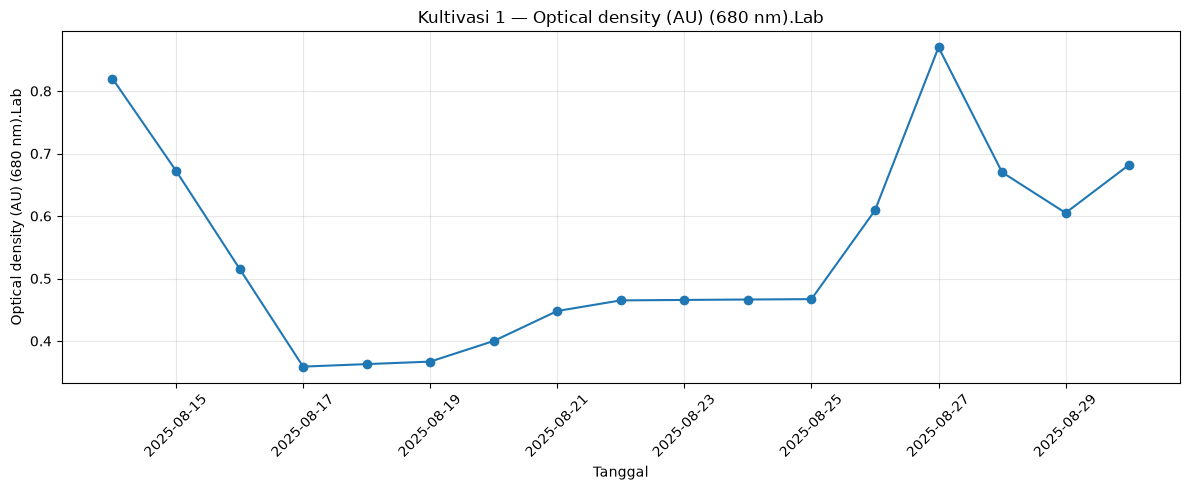

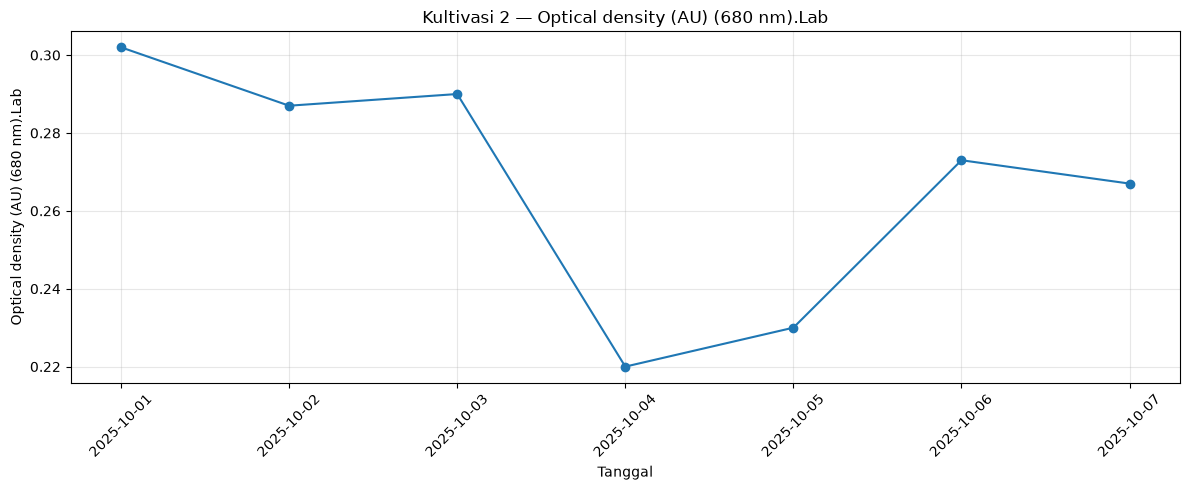

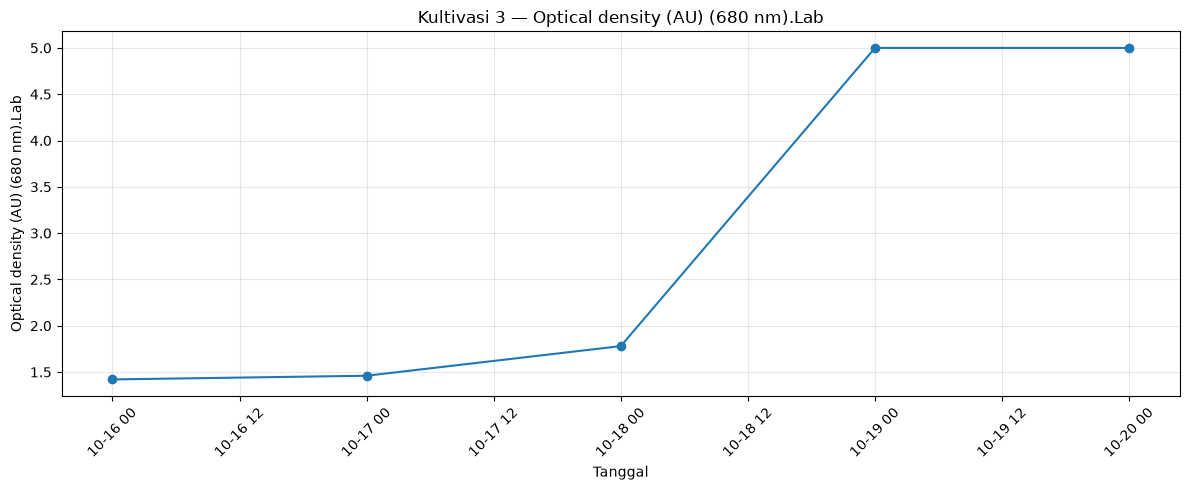

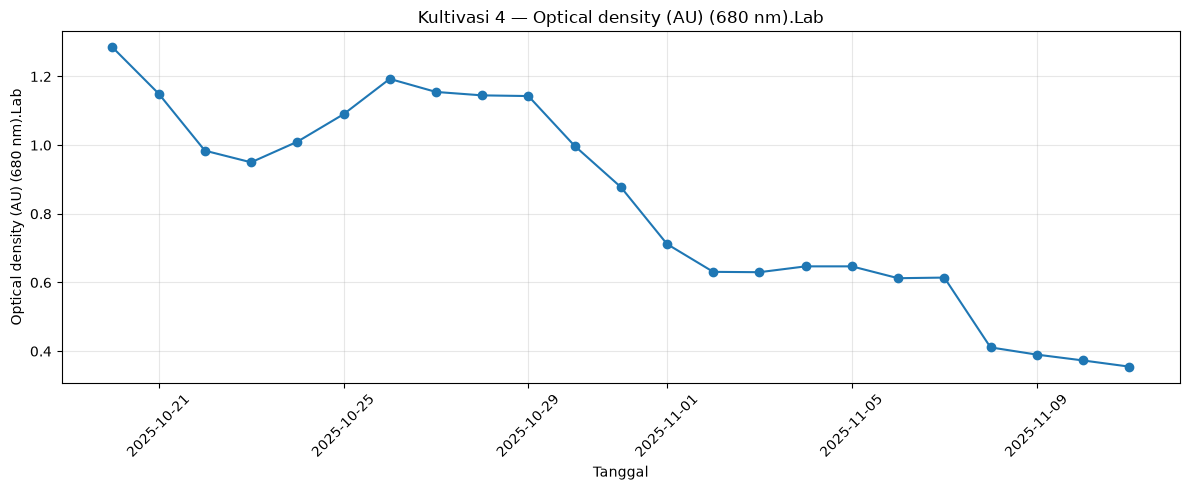

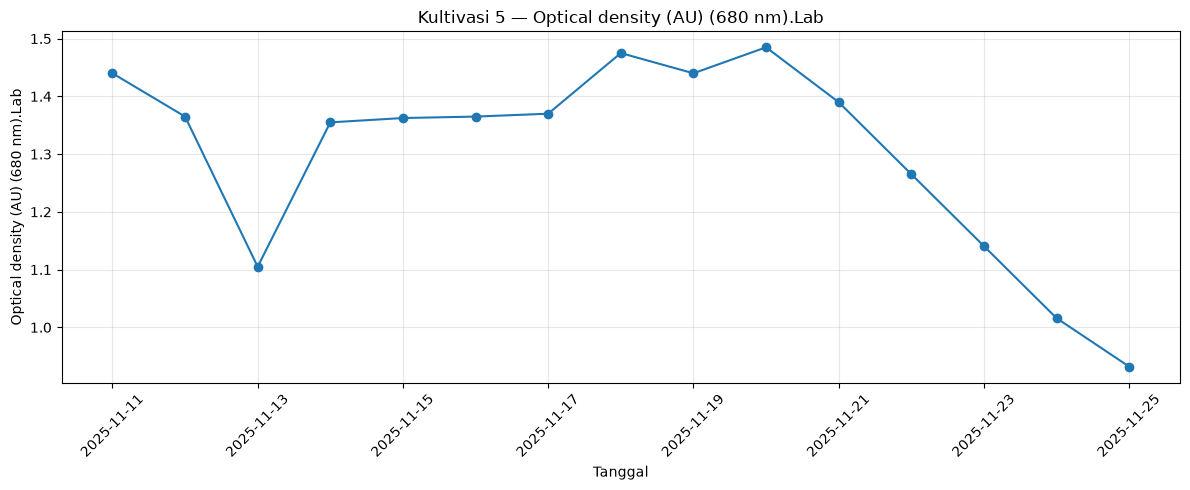

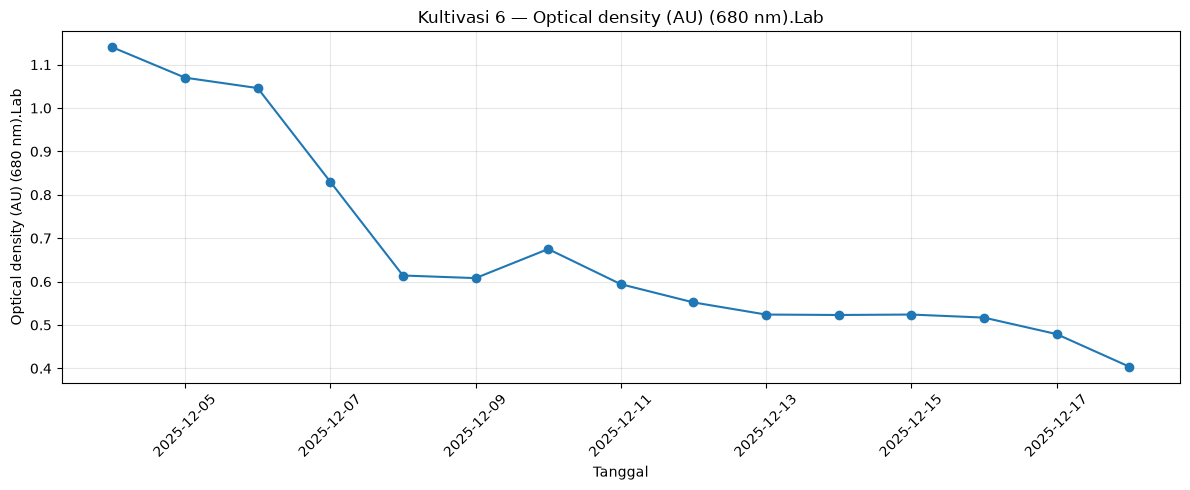

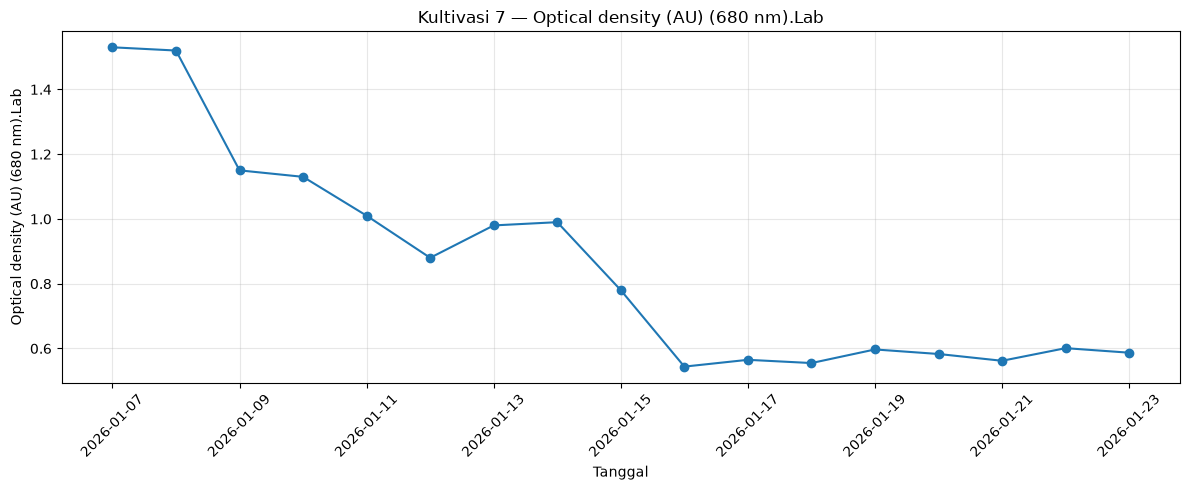

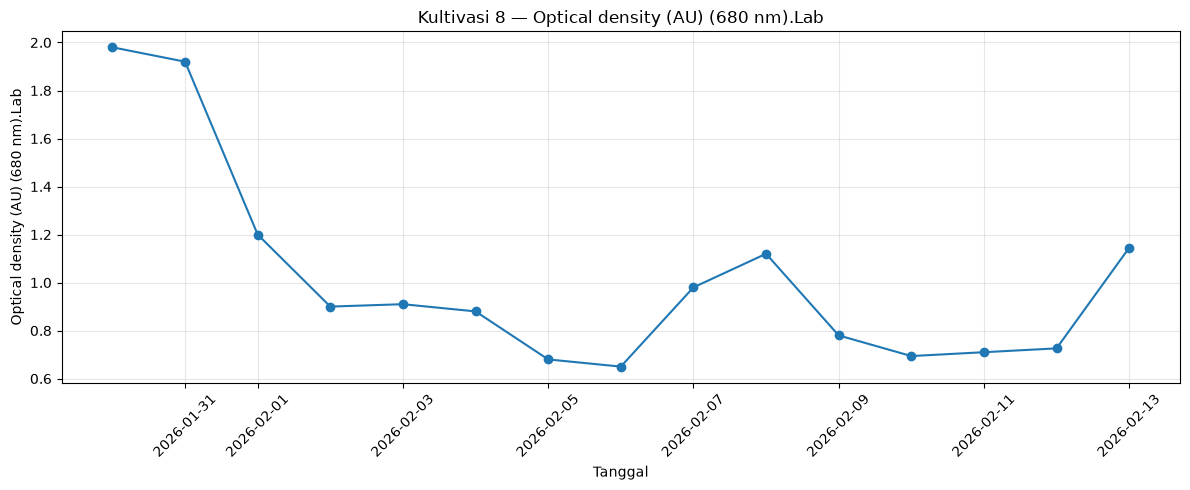

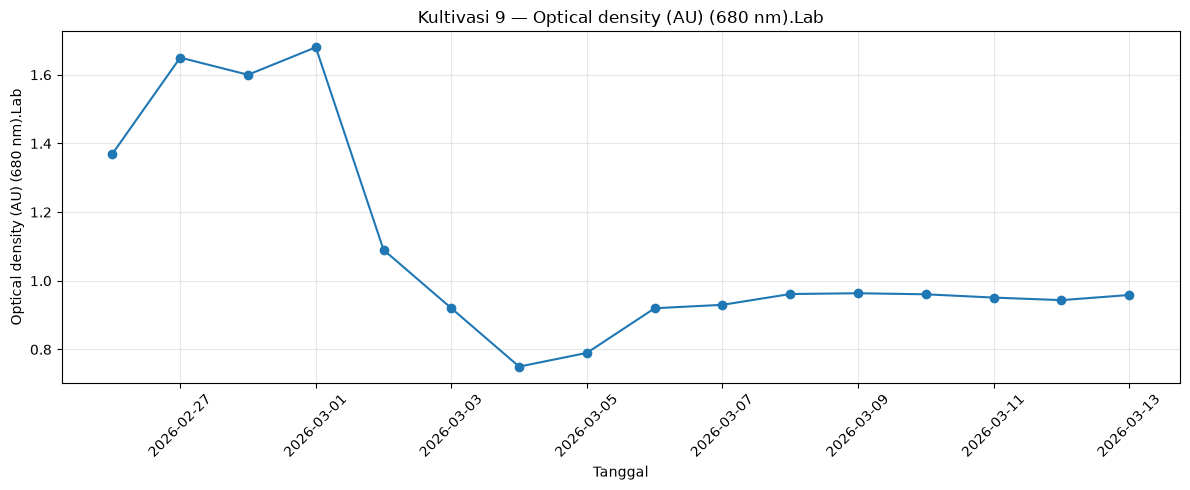

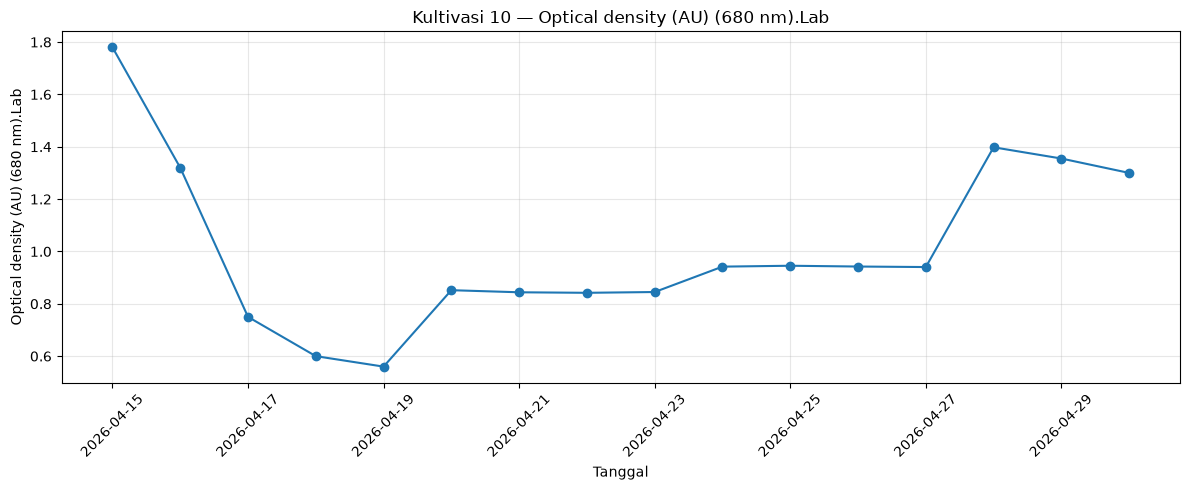

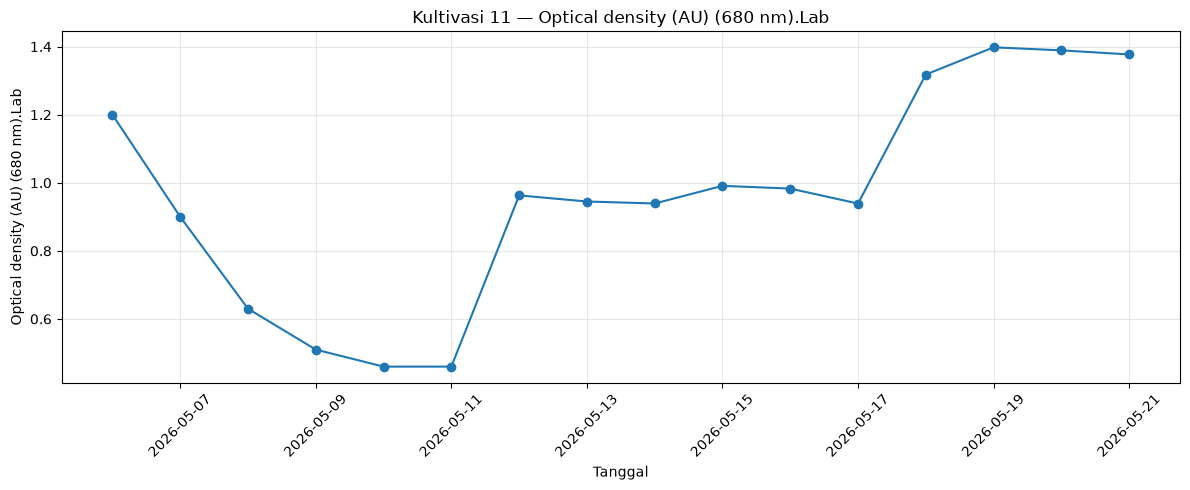

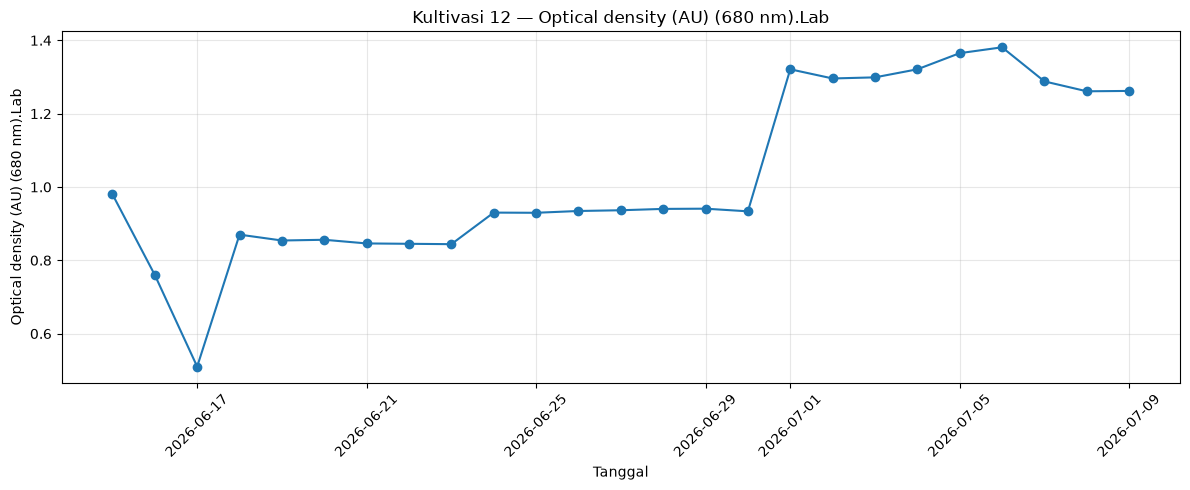

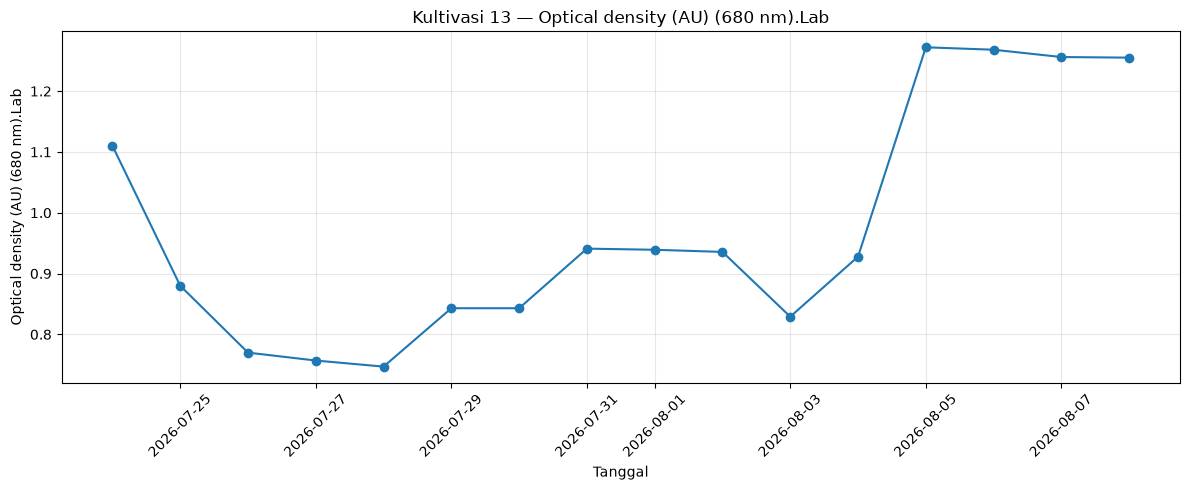

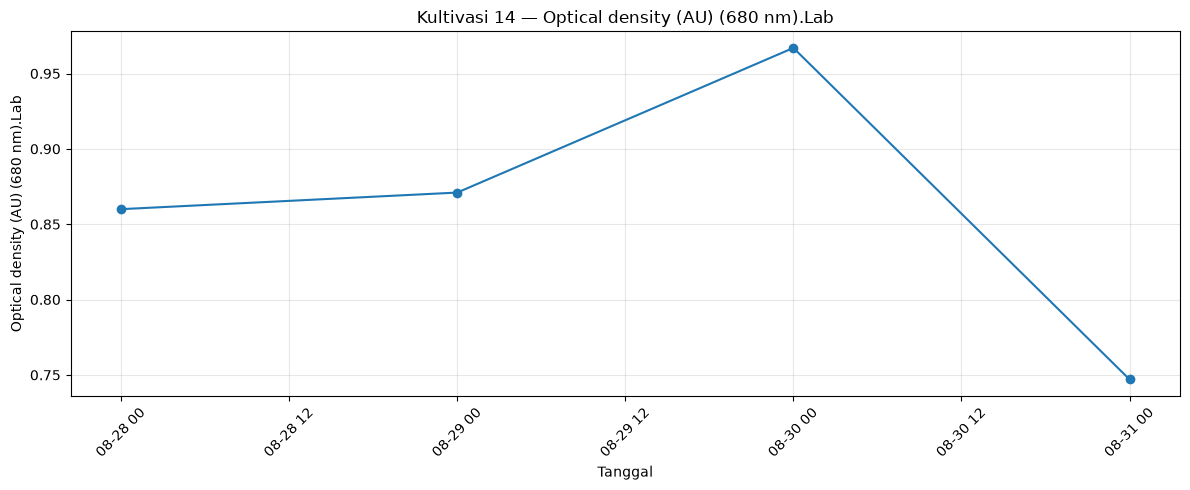

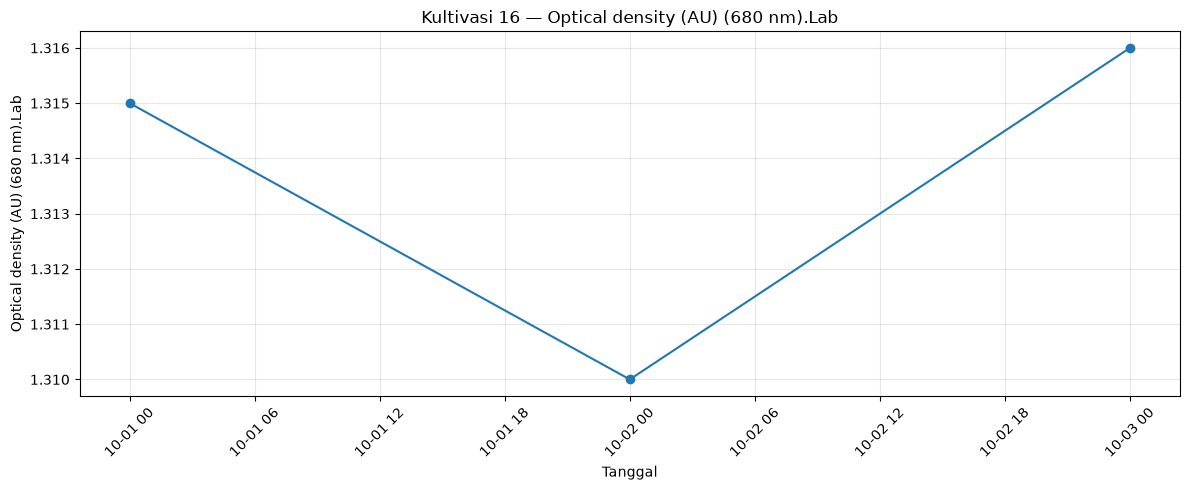

In [72]:

for k, df_asli in sorted(data.items()):
    df = df_asli.copy()

    # Gunakan fungsi parse_tanggal yang sudah dibuat sebelumnya
    df["Tanggal"] = df["Tanggal"].apply(parse_tanggal)
    df[parameter] = pd.to_numeric(df[parameter], errors="coerce")

    plot_df = (
        df.dropna(subset=["Tanggal", parameter])
          .sort_values("Tanggal")
    )

    if plot_df.empty:
        print(f"K{k:02}: tidak ada pasangan tanggal dan nilai {parameter} yang valid.")
        continue

    plt.figure(figsize=(12, 5))
    plt.plot(plot_df["Tanggal"], plot_df[parameter], marker="o")
    plt.title(f"Kultivasi {k} — {parameter}")
    plt.xlabel("Tanggal")
    plt.ylabel(parameter)
    plt.xticks(rotation=45)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

# Waktu pengambilan sensor pada tiap kultivasi pada sensor Non Lab Analog

In [73]:

#! Import Library
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("Data Kultivasi Mikroalga K1-16/per_kultivasi")

parameter = "1_bga(cells/mL)"

data_menit = {}

In [78]:
for nomor in range(1, 17):
    kode = f"K{nomor:02d}"
    file_csv = ROOT / kode / f"{kode}_sensor_menit.csv"

    if not file_csv.exists():
        print(f"{kode}: file tidak ditemukan — {file_csv}")
        continue

    df = pd.read_csv(file_csv)
    df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
    data_menit[nomor] = df

    print(
        f"{kode}: {len(df):,} baris, "
        f"{df['timestamp'].notna().sum():,} timestamp valid"
    )
    
total_baris = sum(len(df) for df in data_menit.values())
print(f"\nTotal baris dari semua kultivasi: {total_baris:,}")

K01: 22,641 baris, 22,641 timestamp valid
K02: 35,653 baris, 35,653 timestamp valid
K03: 5,321 baris, 5,321 timestamp valid
K04: 31,205 baris, 31,205 timestamp valid
K05: 19,765 baris, 19,765 timestamp valid
K06: 19,775 baris, 19,775 timestamp valid
K07: 22,691 baris, 22,691 timestamp valid
K08: 20,036 baris, 20,036 timestamp valid
K09: 21,441 baris, 21,441 timestamp valid
K10: 21,181 baris, 21,181 timestamp valid
K11: 21,061 baris, 21,061 timestamp valid
K12: 34,216 baris, 34,216 timestamp valid
K13: 21,601 baris, 21,601 timestamp valid
K14: 20,051 baris, 20,051 timestamp valid
K15: 2,701 baris, 2,701 timestamp valid
K16: 21,611 baris, 21,611 timestamp valid

Total baris dari semua kultivasi: 340,950


In [75]:

# Lihat nama kolom yang tersedia
if data_menit:
    print("\nKolom tersedia:")
    print(list(next(iter(data_menit.values())).columns))

    if parameter not in next(iter(data_menit.values())).columns:
        raise ValueError(
            f"Kolom '{parameter}' tidak ditemukan. "
            "Pilih nama kolom dari daftar di atas."
        )


Kolom tersedia:
['timestamp', 'kultivasi', 'hari_ke', '1_cod(mg/L)', '1_toc(mg/L)', '1_bod(mg/L)', '1_turbidity(NTU)', '1_do(mg/L)', '1_temp_air(C)', '1_bga(cells/mL)', '1_nh3(mg/L)', '1_ph', '1_tds(ppm)', '1_tss(mg/L)', '1_irradiance(W/m2)', '1_illuminance(Lux)', '2_light(Lux)', '2_o2(ppm)', '2_temp(C)', '2_pressure(hPa)', '2_altitude(m)', '2_humidity(%)', '2_nh3_udara(ppm)', '2_co2(ppm)', 'Pump1_NaHCO3 (mL)', 'Pump2_Molase (mL)', 'Pump3_Microalgae (mL)', 'Aerator_RU (L/s)', 'Lampu (PWM%)', 'Lampu (lux)', 'od680_estimasi(AU)', 'biomassa_estimasi(g/L)', 'berat_kering_estimasi(g)', 'berat_basah_estimasi(g)', 'n_data']


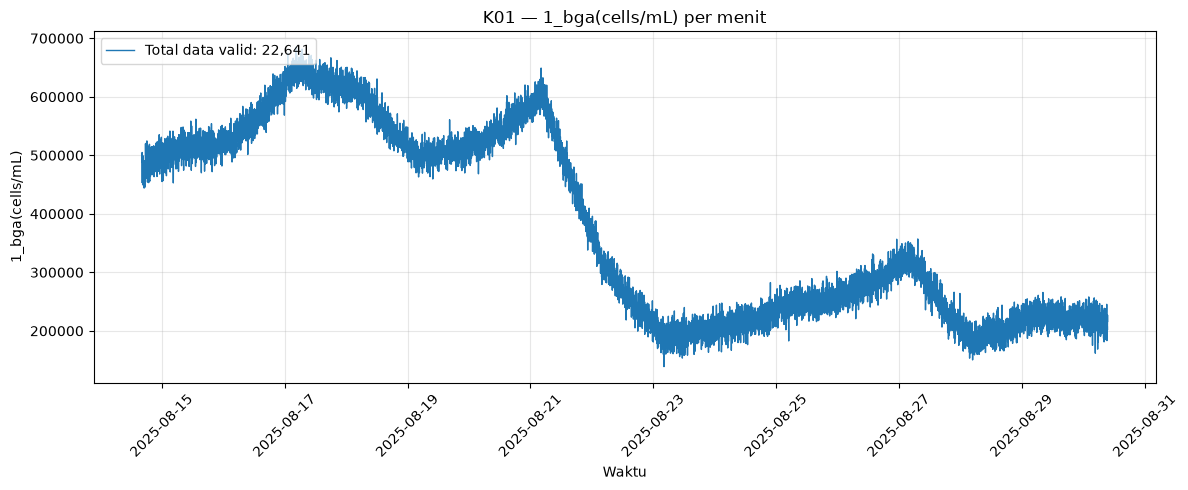

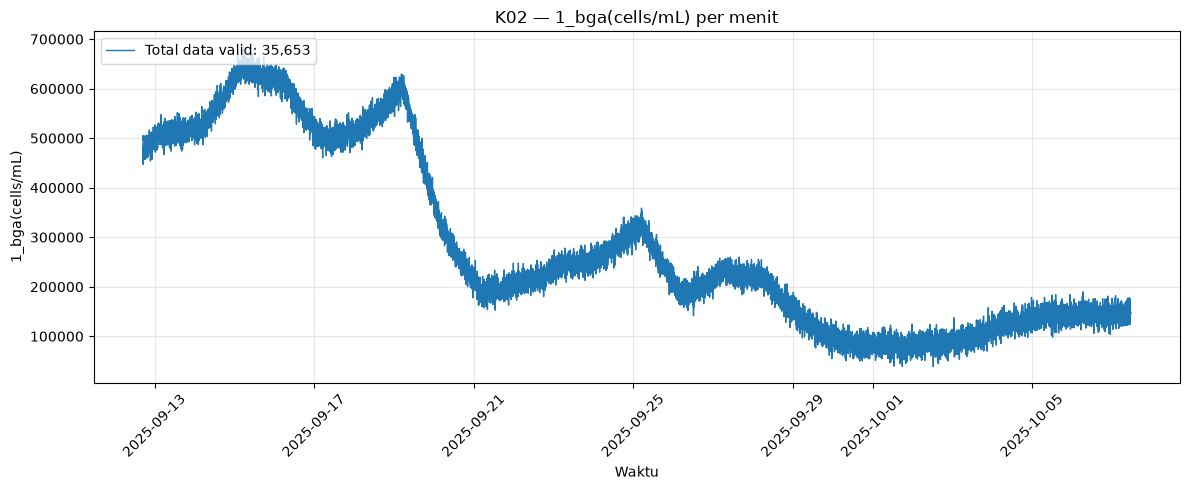

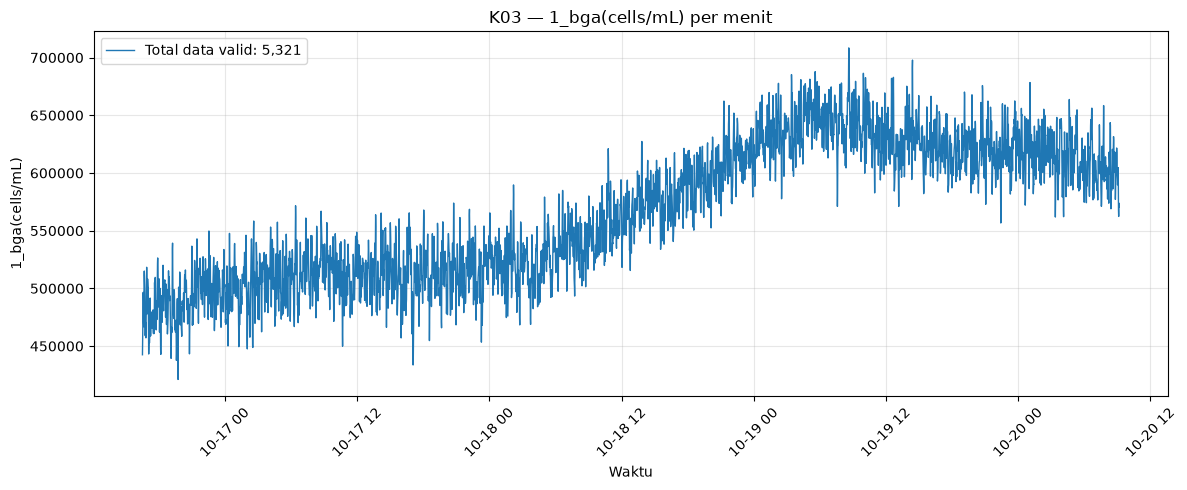

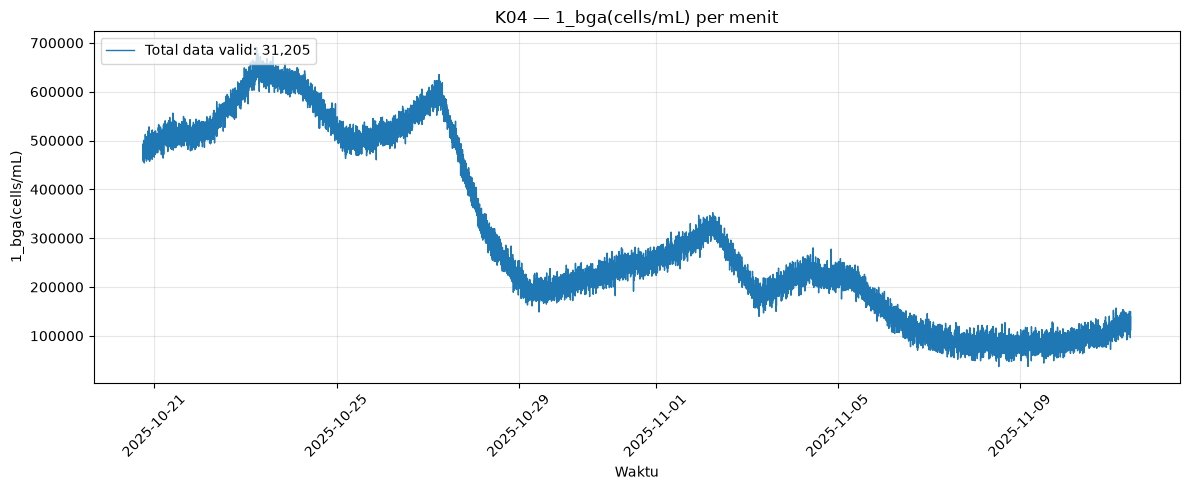

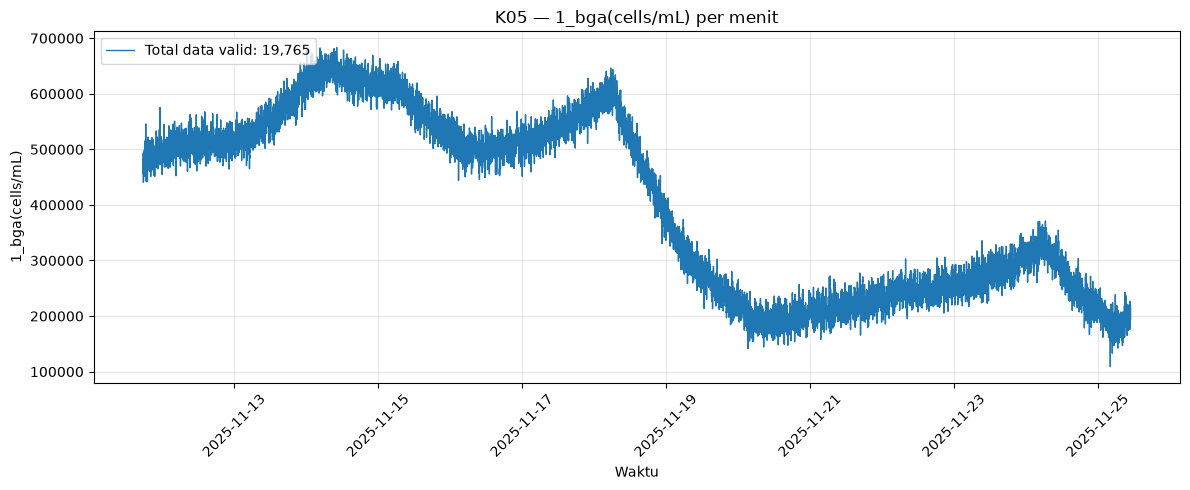

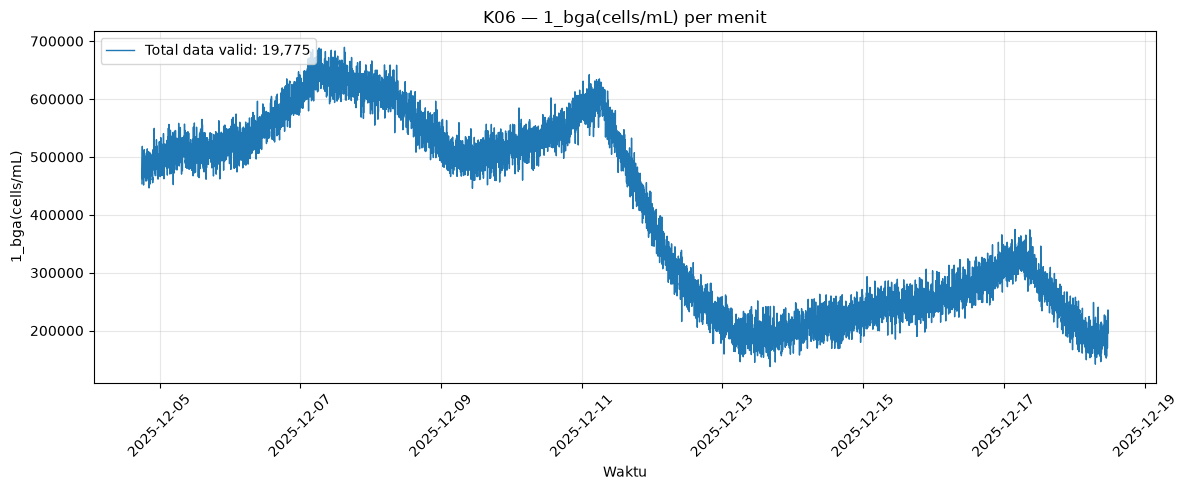

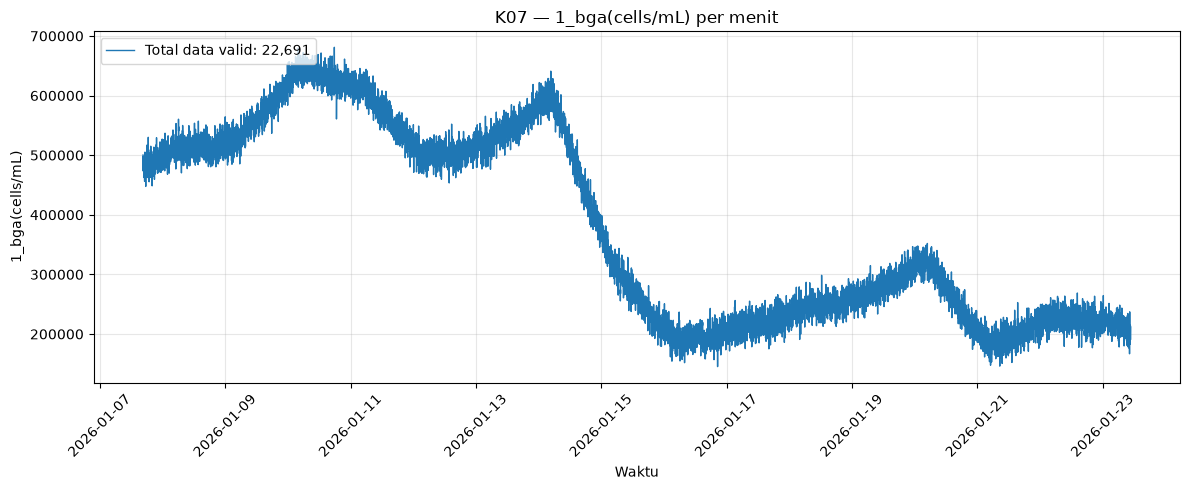

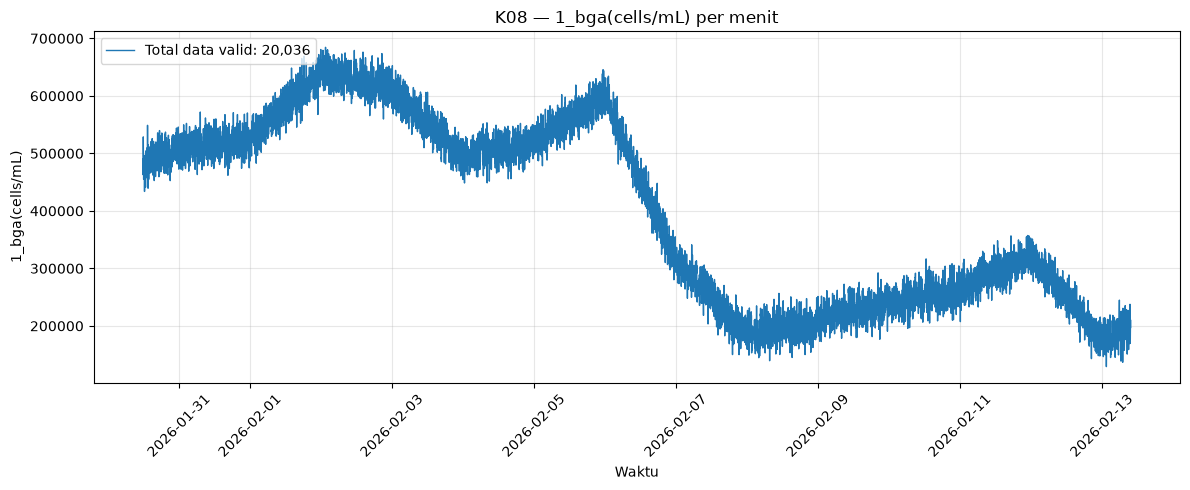

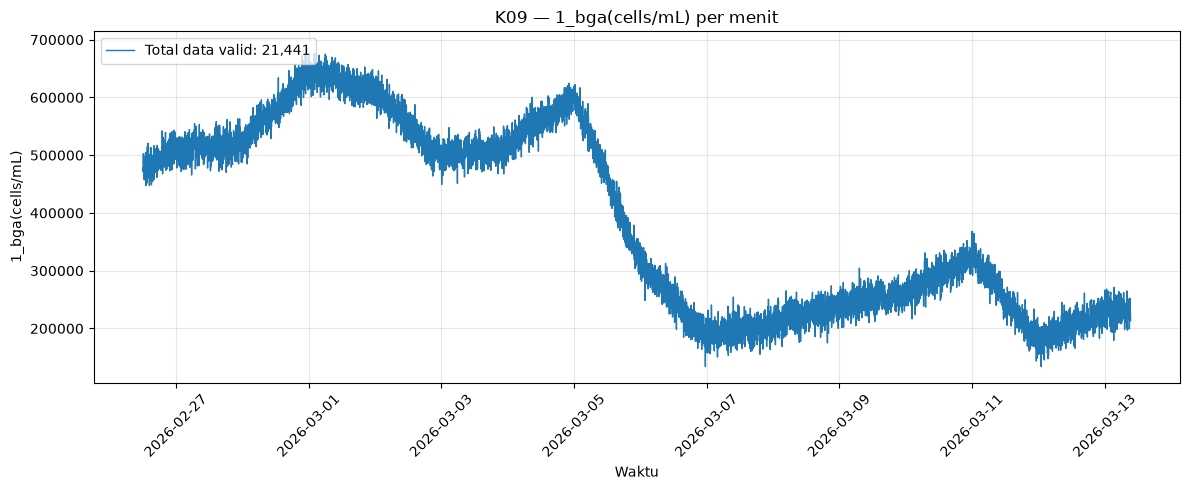

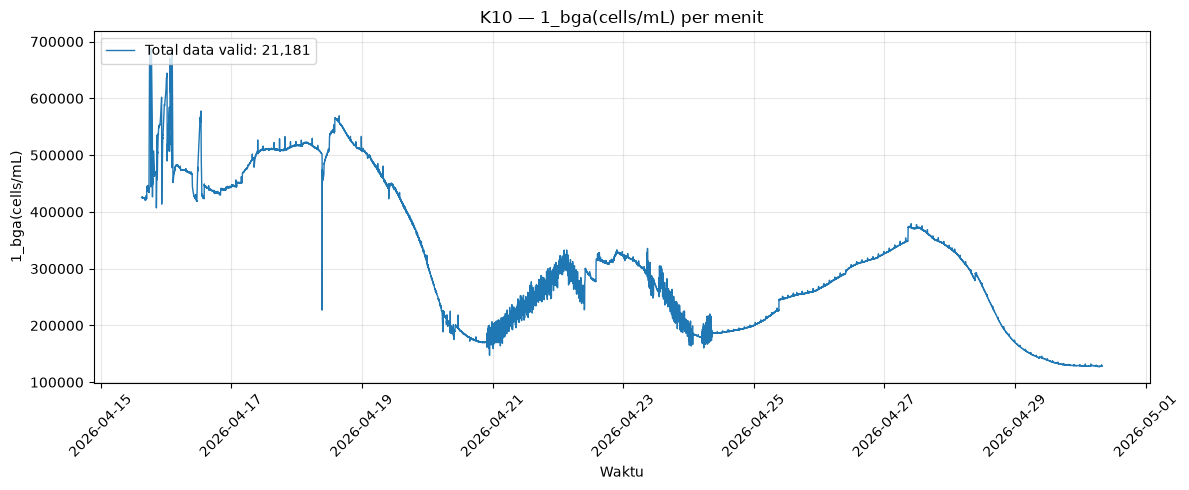

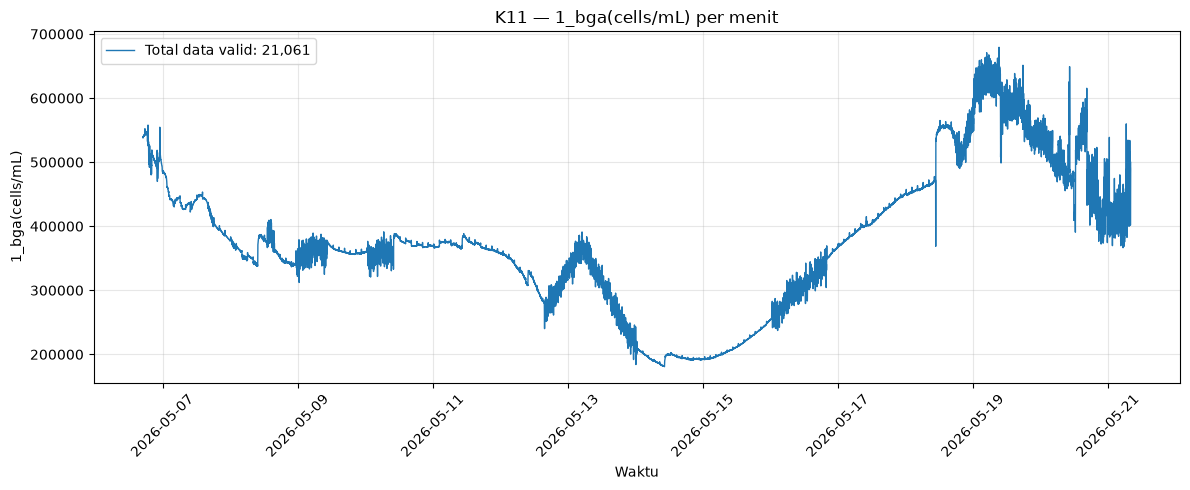

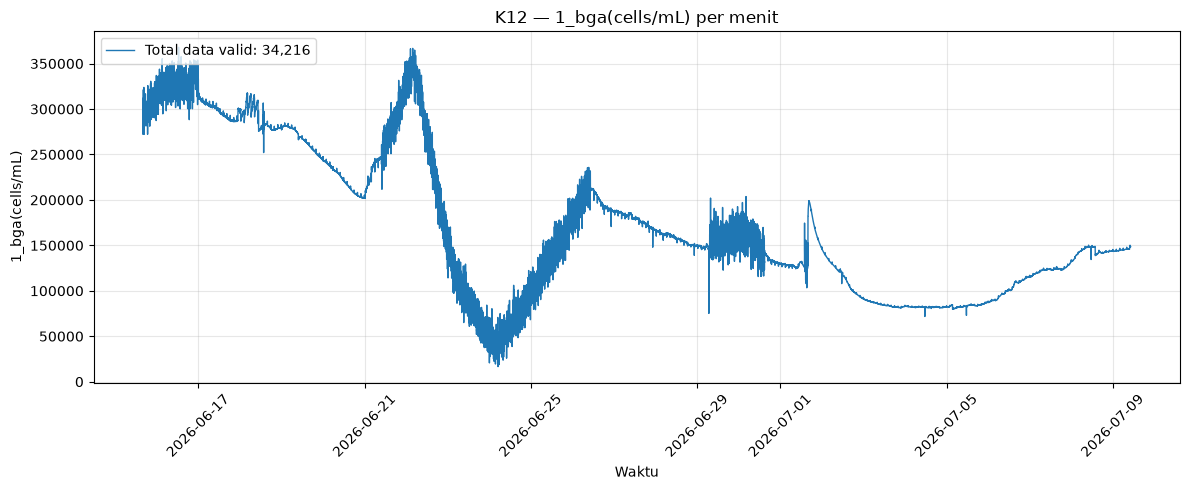

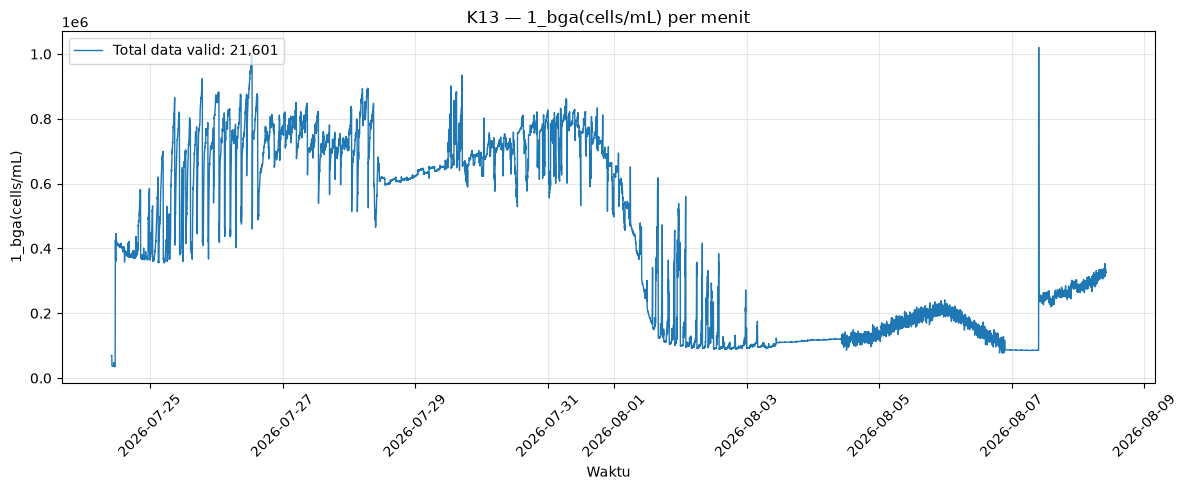

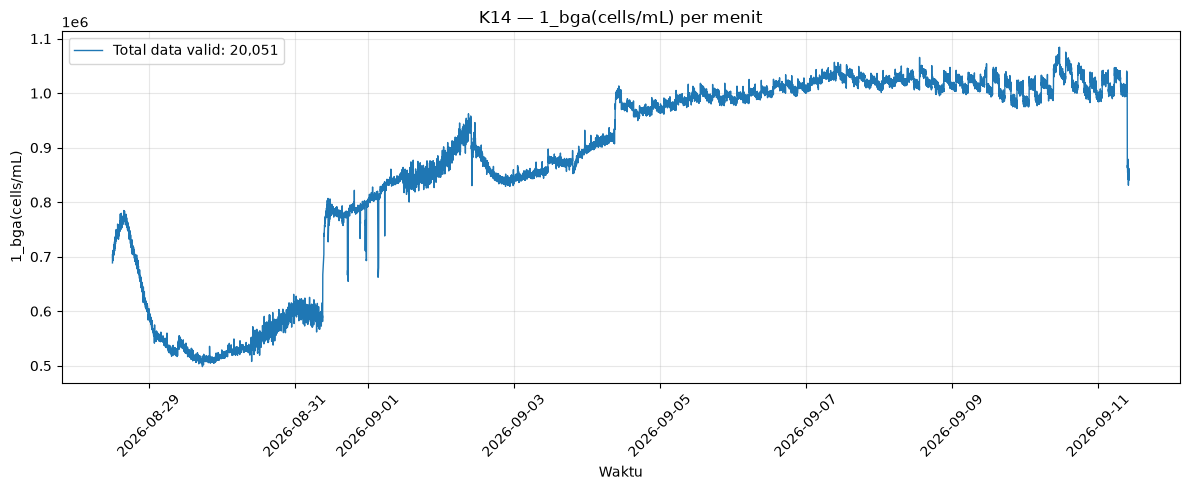

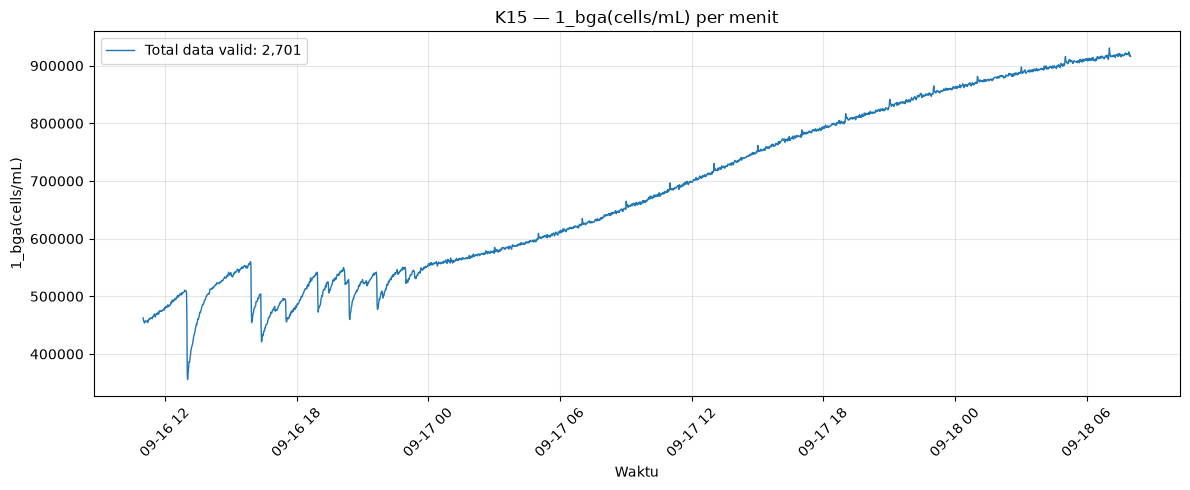

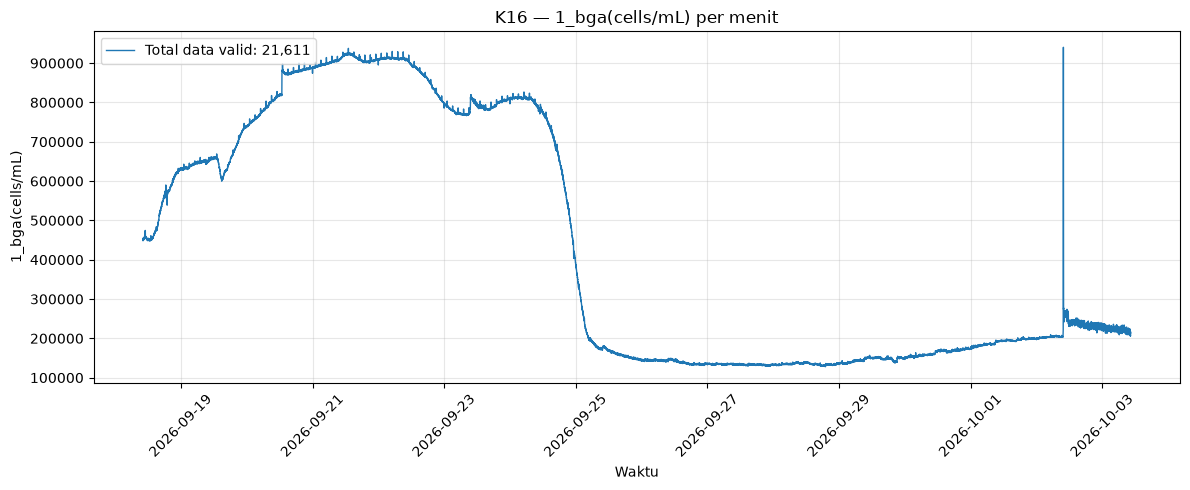

In [77]:
# Plot satu per satu
for nomor, df_asli in sorted(data_menit.items()):
    kode = f"K{nomor:02d}"
    df = df_asli.copy()

    df[parameter] = pd.to_numeric(df[parameter], errors="coerce")
    plot_df = (
        df.dropna(subset=["timestamp", parameter])
          .sort_values("timestamp")
    )

    if plot_df.empty:
        print(f"{kode}: tidak ada data valid untuk {parameter}")
        continue

    plt.figure(figsize=(12, 5))
    plt.plot(plot_df["timestamp"], plot_df[parameter], linewidth=1)
    plt.title(f"{kode} — {parameter} per menit")
    plt.xlabel("Waktu")
    plt.ylabel(parameter)
    plt.legend([f"Total data valid: {len(plot_df):,}"], loc="upper left")
    plt.grid(True, alpha=0.3)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
    plt.close()

# Cek Persebaran Data Sensor Lab Analog

In [87]:
from pathlib import Path
import pandas as pd

file_sensor = Path(
    r"D:\00 Kuliah\TA\Experiment\Dataset\Data Sensor Kultivasi\csv\Lab Analog K1-K16\gabungan_lab_analog.csv"
)

folder_grafik = Path(r"D:\00 Kuliah\TA\Experiment\Eksplorasi data")

df = pd.read_csv(file_sensor, encoding="utf-8-sig")


In [88]:
# Gabungkan tanggal dan waktu untuk sumbu X
tanggal = pd.to_datetime(df["Tanggal"], errors="coerce")
waktu = df["Waktu (jam:menit:detik)"].astype(str).str.strip()

df["_timestamp"] = pd.to_datetime(
    tanggal.dt.strftime("%Y-%m-%d") + " " + waktu,
    errors="coerce",
)

# Pilih kolom sensor numerik; abaikan kolom treatment dan metadata
kolom_sensor = [
    kolom for kolom in df.columns
    if (kolom.endswith(".analog") or kolom.endswith(".Lab"))
    and kolom not in {"Tanggal", "Waktu (jam:menit:detik)"}
]

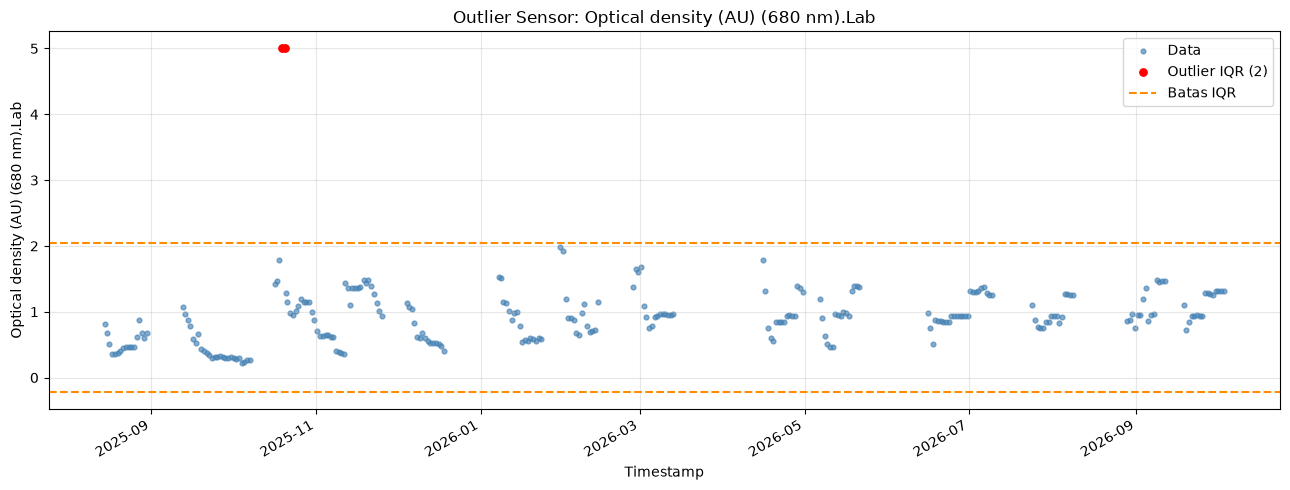

Optical density (AU) (680 nm).Lab: 2 outlier; grafik disimpan.


In [89]:
for kolom in kolom_sensor:
    nilai = pd.to_numeric(df[kolom], errors="coerce")

    data_plot = pd.DataFrame({
        "timestamp": df["_timestamp"],
        "nilai": nilai,
    }).dropna(subset=["timestamp", "nilai"]).sort_values("timestamp")

    if data_plot.empty:
        print(f"{kolom}: tidak ada data numerik yang bisa diplot.")
        continue

    # Batas outlier berdasarkan metode IQR
    q1 = data_plot["nilai"].quantile(0.25)
    q3 = data_plot["nilai"].quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    mask_outlier = (
        (data_plot["nilai"] < batas_bawah)
        | (data_plot["nilai"] > batas_atas)
    )

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.scatter(
        data_plot["timestamp"],
        data_plot["nilai"],
        s=12,
        color="steelblue",
        alpha=0.65,
        label="Data",
    )
    ax.scatter(
        data_plot.loc[mask_outlier, "timestamp"],
        data_plot.loc[mask_outlier, "nilai"],
        s=28,
        color="red",
        label=f"Outlier IQR ({mask_outlier.sum()})",
        zorder=3,
    )

    ax.axhline(batas_bawah, color="darkorange", linestyle="--", label="Batas IQR")
    ax.axhline(batas_atas, color="darkorange", linestyle="--")

    ax.set_title(f"Outlier Sensor: {kolom}")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel(kolom)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.autofmt_xdate()
    fig.tight_layout()

    # Buat nama file yang aman
    nama_file = re.sub(r'[<>:"/\\|?*]+', "_", kolom)
    fig.savefig(folder_grafik / f"{nama_file}.png", dpi=150)

    plt.show()
    plt.close(fig)

    print(f"{kolom}: {mask_outlier.sum()} outlier; grafik disimpan.")

In [110]:
from pathlib import Path
import pandas as pd

file_sensor = Path(
    r"D:\00 Kuliah\TA\Experiment\Dataset\Data Sensor Kultivasi\csv\sel mikroalga\gabungan_sensor_cell_density_with_image.csv"
)

folder_grafik = Path(r"D:\00 Kuliah\TA\Experiment\Eksplorasi data")

df = pd.read_csv(file_sensor, encoding="utf-8-sig")


In [111]:
# Gabungkan tanggal dan waktu untuk sumbu X
tanggal = pd.to_datetime(df["Timestamp_Gambar"], errors="coerce")

df["Timestamp_Gambar"] = pd.to_datetime(
    tanggal.dt.strftime("%Y-%m-%d"),errors="coerce",)

# Pilih kolom sensor numerik; abaikan kolom treatment dan metadata

sensor_dicek = [
    "sensor_1_bga(cells/mL)",
]

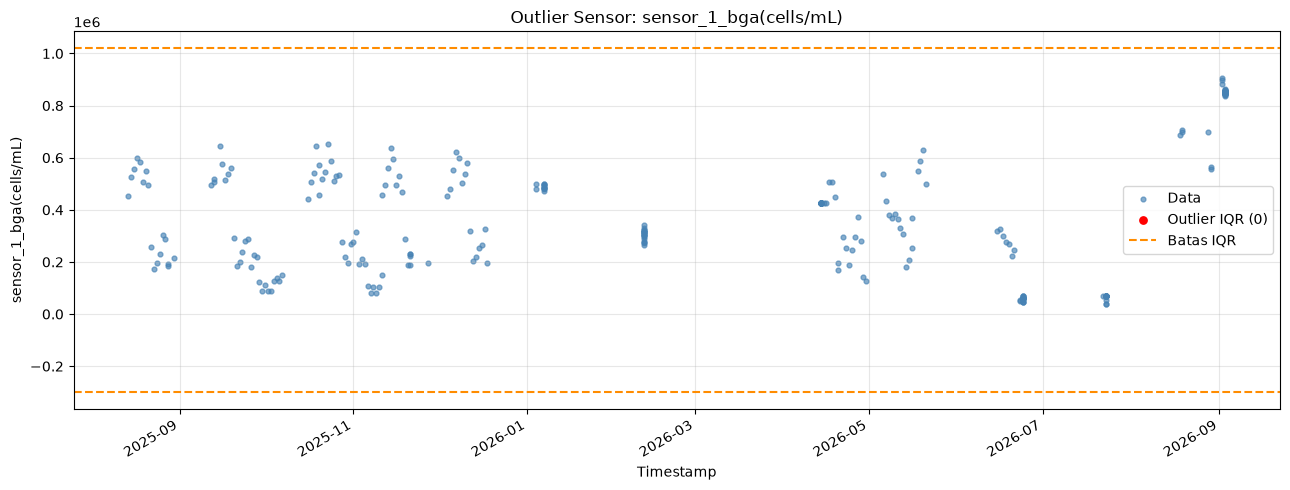

sensor_1_bga(cells/mL): 0 outlier; grafik disimpan.


In [112]:
for kolom in sensor_dicek:
    nilai = pd.to_numeric(df[kolom], errors="coerce")

    data_plot = pd.DataFrame({
        "timestamp": df["Timestamp_Gambar"],
        "nilai": nilai,
    }).dropna(subset=["timestamp", "nilai"]).sort_values("timestamp")

    if data_plot.empty:
        print(f"{kolom}: tidak ada data numerik yang bisa diplot.")
        continue

    # Batas outlier berdasarkan metode IQR
    q1 = data_plot["nilai"].quantile(0.25)
    q3 = data_plot["nilai"].quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr

    mask_outlier = (
        (data_plot["nilai"] < batas_bawah)
        | (data_plot["nilai"] > batas_atas)
    )

    fig, ax = plt.subplots(figsize=(13, 5))

    ax.scatter(
        data_plot["timestamp"],
        data_plot["nilai"],
        s=12,
        color="steelblue",
        alpha=0.65,
        label="Data",
    )
    ax.scatter(
        data_plot.loc[mask_outlier, "timestamp"],
        data_plot.loc[mask_outlier, "nilai"],
        s=28,
        color="red",
        label=f"Outlier IQR ({mask_outlier.sum()})",
        zorder=3,
    )

    ax.axhline(batas_bawah, color="darkorange", linestyle="--", label="Batas IQR")
    ax.axhline(batas_atas, color="darkorange", linestyle="--")

    ax.set_title(f"Outlier Sensor: {kolom}")
    ax.set_xlabel("Timestamp")
    ax.set_ylabel(kolom)
    ax.grid(True, alpha=0.3)
    ax.legend()
    fig.autofmt_xdate()
    fig.tight_layout()

    # Buat nama file yang aman
    nama_file = re.sub(r'[<>:"/\\|?*]+', "_", kolom)
    fig.savefig(folder_grafik / f"{nama_file}.png", dpi=150)

    plt.show()
    plt.close(fig)

    print(f"{kolom}: {mask_outlier.sum()} outlier; grafik disimpan.")